# ChronoClone Weinreb manuscript revision

## Scope
Rewrite the manuscript through Weinreb for the new Google Doc only.
The old Google Doc and old manuscript source are protected. No Singh analysis,
metaclone refitting, gene-program refitting, or package modification is performed.
At the authors' subsequent request, within-day clone-median omnibus tests are added
to the pseudotime panels, with a fixed joint multiple-testing family. Existing
gene-program contrasts receive visible significance annotations without refitting.
Existing figure-source tables support presentation changes, HSPC aggregation,
and direct displays of already calculated branch occupancies and distances.
The retained original pipeline and ODE illustrations are unchanged.

## Environment and execution
Environment **chronoclone**, existing Conda-compatible installation at
`/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone`.
No environment installation or mutation. Versions are printed below.
Execute with:
`/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/0001_manuscript_panels_and_evidence.ipynb`

This notebook is scaffolded by `build_revision_notebook.py`; its executed cells
are the reproducible entry point. Each plot-output cell includes its data
shaping, construction, editable SVG export, and display. Inherited images may
contain the original raster layers, which are not represented as new vectors.
Chart policy: existing MC palette; common cell-state palette with pooled HSPCs;
no narrative text or titles inside panels, only functional labels and keys.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, shutil, re, subprocess, platform
import importlib.metadata as im
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910'
for name in ['figures','tables','reports','pre_edit_snapshot','runtime']:
    (OUT/name).mkdir(parents=True,exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'runtime/matplotlib')
import pandas as pd
import numpy as np
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from IPython.display import display, SVG
ENV=Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).resolve()==(ENV/'bin/python').resolve()
environment={'environment':'chronoclone','path':str(ENV),'manager':'Existing Conda-compatible environment; no mutation','kernel':'chronoclone','Python':platform.python_version(),**{p:im.version(p) for p in ['numpy','pandas','matplotlib','anndata','nbformat','scipy','statsmodels']}}
display(pd.DataFrame(environment.items(),columns=['field','value']))
(OUT/'reports/environment.json').write_text(json.dumps(environment,indent=2))
OLD=ROOT/'analysis_workspace/manuscript/chronoclone_panel_revision_20260910'
OLD_MS=ROOT/'analysis_workspace/manuscript_drafts/chronoclone_weinreb_manuscript_20260901/manuscript.md'
BENCH=ROOT/'analysis_workspace/benchmarks/chronoclone_method_noise_benchmark_day0_locked_20260812'
ANCESTRY=ROOT/'analysis_workspace/weinreb/weinreb_metaclone_ancestry_worked_examples_20260910'
MULTI=ROOT/'analysis_workspace/weinreb/weinreb_multilineage_metaclone_dynamics_20260901'
PROGRAM=ROOT/'analysis_workspace/weinreb/weinreb_day2_hspc_metaclone_gene_programs_20260902'
FIG=OUT/'figures'
NODE='~/.cache/research-runtimes/research-primary-runtime/dependencies/node/bin/node'
def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
assert sha256(OLD_MS)=='23c7a92a3d4a78f65d3fbf0020beb258b65076c5f21c53cea51fba75165ca088'
if not (OUT/'pre_edit_snapshot/prior_manuscript.md').exists(): shutil.copy2(OLD_MS,OUT/'pre_edit_snapshot/prior_manuscript.md')
export=Path('/tmp/exports/ChronoClone v3-169d8fdf-7d23-4744-a6af-25acee8fd4a7.docx')
if export.exists() and not (OUT/'pre_edit_snapshot/new_google_doc_before.docx').exists(): shutil.copy2(export,OUT/'pre_edit_snapshot/new_google_doc_before.docx')
source_manifest=pd.read_csv(OLD/'reports/panel_manifest.csv')
for _,row in source_manifest.iterrows():
    assert sha256(ROOT/row.svg)==row.svg_sha256
    assert sha256(ROOT/row.png)==row.png_sha256
print('Registered source SVG/PNG assets verified:',len(source_manifest))
PALETTE=pd.read_csv(ROOT/'analysis_workspace/manuscript/chronoclone_manuscript_panel_styling_20260907/tables/manuscript_metaclone_palette.csv').set_index('label').color.to_dict()
INPUT=ROOT/'reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad'
assert sha256(INPUT)=='4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911'
A=ad.read_h5ad(INPUT,backed='r')
obs=A.obs.copy()
coordinates={key:np.asarray(A.obsm[key]) for key in A.obsm.keys()}
state_order=list(obs.cell_type.cat.categories)
STATE_COLORS=dict(zip(state_order,A.uns['cell_type_colors']))
A.file.close()
print('Coordinates:',{k:v.shape for k,v in coordinates.items()})
display(pd.DataFrame({'state':state_order,'color':[STATE_COLORS[s] for s in state_order]}))
print('Observed days:',obs.day.value_counts().to_dict())
NS='{http://www.w3.org/2000/svg}'
ET.register_namespace('',NS[1:-1]);ET.register_namespace('xlink','http://www.w3.org/1999/xlink')
mpl.rcParams.update({'svg.fonttype':'none','font.family':'DejaVu Sans','font.size':13,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','savefig.facecolor':'white'})
panel_records=[]

,field,value
0,environment,chronoclone
1,path,~/.reference-science/conda/envs/...
2,manager,Existing Conda-compatible environment; no muta...
3,kernel,chronoclone
4,Python,3.11.15
5,numpy,2.4.6
6,pandas,2.3.3
7,matplotlib,3.11.0
8,anndata,0.12.18
9,nbformat,5.10.4


Registered source SVG/PNG assets verified: 44


Coordinates: {'DM_EigenVectors': (9714, 10), 'DM_EigenVectors_multiscaled': (9714, 5), 'X_pca': (9714, 50), 'X_umap': (9714, 2), 'branch_masks': (9714, 5), 'clone_matrix': (), 'palantir_fate_probabilities': (9714, 5)}


,state,color
0,Baso,#023fa5
1,DC,#7d87b9
2,Eos,#bec1d4
3,Ery,#d6bcc0
4,Ly,#bb7784
5,Mast,#8e063b
6,Meg,#4a6fe3
7,Mono,#8595e1
8,Neu,#b5bbe3
9,early_prog_Neu,#e6afb9


Observed days: {6: 5372, 4: 3301, 2: 1041}


## Existing quantitative evidence

In [2]:
effects=pd.read_csv(ANCESTRY/'tables/evidence_review_selected_examples.csv')
display(effects)
occupancy=pd.read_csv(ANCESTRY/'tables/ancestry_03_multilineage_branch_occupancy_change.csv')
pair_distances=pd.read_csv(ANCESTRY/'tables/ancestry_multilineage_branch_pair_distances.csv')
display(occupancy)
display(pair_distances[(pair_distances.cohort=='day2_hspc_linked')&(pair_distances.estimator=='clone_balanced_occupancy')])
config=json.loads((BENCH/'config/benchmark_config.json').read_text())
print('Benchmark display time labels:', ['t1','t2','t3','t4'])
print('Registered method parameters:', {k:config[k] for k in ['repeats','master_seed','min_persistence','min_total_count','chronoclone','clades','generic_baselines']})
print('Benchmark summary columns:',pd.read_csv(BENCH/'results/aggregate/native_method_noise_summary.csv',nrows=1).columns.tolist())

,example_id,program,contrast_id,effect_sd,qvalue,ci_low,ci_high,effect_and_q_match,source_fraction_effect,source_fraction_support,...,prog2_only_effect_fixed_scale,prog2_supported,prog2_summary_matches,nonmito_effect_fixed_scale,nonmito_supported,nonmito_native_qvalue,nonmito_summary_matches,LOO_supported,LOO_same_direction,LOO_summary_matches
0,mono_1,Inflammatory Response,Monocyte_fast_minus_slow,0.584366,0.002291,0.258275,0.910457,True,0.591816,True,...,0.483511,True,True,1.509380,True,0.000018,True,7,7,True
1,mono_2,Myc Targets V2,Monocyte_fast_minus_slow,0.551171,0.001083,0.269237,0.833105,True,0.531578,True,...,0.529570,True,True,1.273948,True,0.000032,True,7,7,True
2,multi_divergence,Interferon Alpha Response,MC5_vs_MC3,-0.818470,0.031454,-1.338296,-0.298645,True,0.084868,True,...,0.326580,False,True,-0.569284,True,0.114080,True,7,7,True
3,multi_convergence,Interferon Alpha Response,MC3_vs_MC18,0.928651,0.004048,0.463530,1.393772,True,0.021021,True,...,-0.266853,False,True,0.984823,True,0.002067,True,7,7,True


,cohort,metaclone,branch,day4_fraction,day6_fraction,day6_minus_day4_percentage_points,n_day4_observed_clones,n_day6_observed_clones,n_day4_branch_cells,n_day6_branch_cells,n_day4_total_cells,n_day6_total_cells,metaclone_display_order,branch_display_order
0,day2_hspc_linked,0,Baso,0.009524,0.001076,-0.844792,35,35,1,3,391,778,0,0
1,day2_hspc_linked,0,Mono,0.195187,0.244153,4.896603,35,35,99,214,391,778,0,2
2,day2_hspc_linked,0,Neu,0.688550,0.735053,4.650309,35,35,238,542,391,778,0,1
3,day2_hspc_linked,2,Baso,0.308333,0.450000,14.166667,20,12,16,34,58,68,1,0
4,day2_hspc_linked,2,Mono,0.205833,0.000000,-20.583333,20,12,11,0,58,68,1,2
5,day2_hspc_linked,2,Neu,0.555833,0.384596,-17.123737,20,12,34,16,58,68,1,1
6,day2_hspc_linked,3,Baso,0.148003,0.060087,-8.791538,50,47,26,27,253,683,3,0
7,day2_hspc_linked,3,Mono,0.469230,0.388558,-8.067259,50,47,96,232,253,683,3,2
8,day2_hspc_linked,3,Neu,0.726449,0.471231,-25.521821,50,47,170,358,253,683,3,1
9,day2_hspc_linked,4,Baso,0.237302,0.330714,9.341270,21,10,15,17,79,57,5,0


,cohort,example,metaclone_a,metaclone_b,estimator,day4_distance,day6_distance,distance_change,observed_direction,coordinate_system
4,day2_hspc_linked,MC5–MC3 previously described divergence,5,3,clone_balanced_occupancy,0.367499,0.522587,0.155088,divergence,Euclidean distance in three overlapping Baso/N...
6,day2_hspc_linked,MC3–MC18 previously described convergence,3,18,clone_balanced_occupancy,0.441630,0.259673,-0.181958,convergence,Euclidean distance in three overlapping Baso/N...


Benchmark display time labels: ['t1', 't2', 't3', 't4']
Registered method parameters: {'repeats': 100, 'master_seed': 20260729, 'min_persistence': 2, 'min_total_count': 3, 'chronoclone': {'n_neighbors': 15, 'resolutions': [1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0], 'thresholds': [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4, 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.7, 0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8, 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9], 'algorithm_seed': 0, 'postfit_silhouette_filter': {'operator': '>=', 'cutoff': 

## Requested within-day pseudotime significance
The authors requested significance marks for differences between metaclones within
each day. Use a Kruskal–Wallis omnibus test on one finite branch-pseudotime
median per clone, including metaclones with at least three informative clones.
The fixed BH family comprises twelve unique branch/output-class/day tests:
neutrophil-output and monocyte-output groups at Days 2/4/6, and the five selected
multilineage metaclones on Baso/Neu/Mono branches at Days 4/6. Repeated display
in cell-violin and clone-dot panels does not add tests to this family.
Non-estimable tests retain P=1 in the correction family. The previously saved
six multilineage omnibus P values are checked, not replaced or erased.
These conditional within-atlas comparisons neither establish pairwise
differences for every MC pair nor independently validate the discovered groups.

In [3]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
PSEUDOTIME_TEST_DESIGNS={
    'neutrophil_output':{'branch':'Neu','mcs':[1,22,9,16,14],'days':[2,4,6]},
    'monocyte_output':{'branch':'Mono','mcs':[6,8,7,12],'days':[2,4,6]},
    'multilineage_Baso':{'branch':'Baso','mcs':[0,2,5,3,18],'days':[4,6]},
    'multilineage_Neu':{'branch':'Neu','mcs':[0,2,5,3,18],'days':[4,6]},
    'multilineage_Mono':{'branch':'Mono','mcs':[0,2,5,3,18],'days':[4,6]},
}
test_rows=[];test_data=[]
for context,spec in PSEUDOTIME_TEST_DESIGNS.items():
    cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
    cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
    cells=cells[np.isfinite(cells.pseudotime)]
    medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True,as_index=False).pseudotime.median()
    assert not medians.duplicated(['metaclone','day','LARRY_ID']).any()
    test_data.append(medians.assign(context=context,branch=spec['branch']))
    for day in spec['days']:
        block=medians[medians.day==day]
        arrays={mc:block.loc[block.metaclone==mc,'pseudotime'].to_numpy(float) for mc in spec['mcs']}
        included=[mc for mc in spec['mcs'] if len(arrays[mc])>=3]
        supported=len(included)>=2
        result=kruskal(*(arrays[mc] for mc in included)) if supported else None
        test_rows.append({'context':context,'branch':spec['branch'],'day':day,'metaclones_declared':'|'.join('MC'+str(mc) for mc in spec['mcs']),'metaclones_tested':'|'.join('MC'+str(mc) for mc in included),'metaclones_below_support':'|'.join('MC'+str(mc) for mc in spec['mcs'] if mc not in included),'n_clones_by_metaclone':json.dumps({str(mc):len(arrays[mc]) for mc in spec['mcs']}),'estimable':supported,'kruskal_H':float(result.statistic) if supported else np.nan,'p_value':float(result.pvalue) if supported else 1.0})
pseudotime_tests=pd.DataFrame(test_rows)
assert len(pseudotime_tests)==12
pseudotime_tests['q_value']=multipletests(pseudotime_tests.p_value,method='fdr_bh')[1]
pseudotime_tests['symbol']=['NE' if not row.estimable else '**' if row.q_value<.05 else '*' if row.q_value<.10 else 'ns' for row in pseudotime_tests.itertuples()]
pseudotime_tests['test_family']='12 within-day clone-median Kruskal-Wallis tests'
pseudotime_tests['interpretation']='Conditional within-atlas omnibus difference; not a pairwise or independent-discovery test'
legacy=pd.read_csv(MULTI/'tables/branch_clone_median_kruskal_tests.csv')
for row in legacy.itertuples():
    current=pseudotime_tests[(pseudotime_tests.context=='multilineage_'+row.branch)&(pseudotime_tests.day==row.day)].iloc[0]
    assert np.isclose(current.kruskal_H,row.kruskal_H,rtol=1e-10)
    assert np.isclose(current.p_value,row.p_value,rtol=1e-10,atol=0)
pd.concat(test_data,ignore_index=True).to_csv(OUT/'tables/pseudotime_omnibus_clone_medians.csv',index=False)
pseudotime_tests.to_csv(OUT/'tables/pseudotime_within_day_omnibus_tests.csv',index=False)
display(pseudotime_tests)
print('Saved historical multilineage H and P values unchanged; displayed q values use the declared joint 12-test family.')

,context,branch,day,metaclones_declared,metaclones_tested,metaclones_below_support,n_clones_by_metaclone,estimable,kruskal_H,p_value,q_value,symbol,test_family,interpretation
0,neutrophil_output,Neu,2,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC9|MC16|MC14,,"{""1"": 17, ""22"": 14, ""9"": 24, ""16"": 13, ""14"": 21}",True,68.777711,4.111274e-14,8.222548e-14,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
1,neutrophil_output,Neu,4,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC9|MC16|MC14,,"{""1"": 16, ""22"": 15, ""9"": 29, ""16"": 20, ""14"": 26}",True,83.130277,3.780453e-17,1.512181e-16,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
2,neutrophil_output,Neu,6,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC16|MC14,MC9,"{""1"": 17, ""22"": 17, ""9"": 2, ""16"": 20, ""14"": 26}",True,71.263620,2.289003e-15,6.867008e-15,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
3,monocyte_output,Mono,2,MC6|MC8|MC7|MC12,MC6|MC8|MC7|MC12,,"{""6"": 32, ""8"": 36, ""7"": 9, ""12"": 23}",True,22.582287,4.934401e-05,5.921281e-05,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
4,monocyte_output,Mono,4,MC6|MC8|MC7|MC12,MC6|MC8|MC7|MC12,,"{""6"": 24, ""8"": 31, ""7"": 21, ""12"": 41}",True,65.727544,3.505272e-14,8.222548e-14,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
5,monocyte_output,Mono,6,MC6|MC8|MC7|MC12,MC6|MC8|MC12,MC7,"{""6"": 29, ""8"": 33, ""7"": 2, ""12"": 41}",True,53.626474,2.265475e-12,3.883671e-12,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
6,multilineage_Baso,Baso,4,MC0|MC2|MC5|MC3|MC18,MC2|MC5|MC3|MC18,MC0,"{""0"": 1, ""2"": 9, ""5"": 4, ""3"": 16, ""18"": 25}",True,15.799934,1.246265e-03,1.359562e-03,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
7,multilineage_Baso,Baso,6,MC0|MC2|MC5|MC3|MC18,MC2|MC5|MC3|MC18,MC0,"{""0"": 2, ""2"": 7, ""5"": 3, ""3"": 8, ""18"": 12}",True,12.023502,7.303084e-03,7.303084e-03,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
8,multilineage_Neu,Neu,4,MC0|MC2|MC5|MC3|MC18,MC0|MC2|MC5|MC3|MC18,,"{""0"": 34, ""2"": 14, ""5"": 21, ""3"": 45, ""18"": 32}",True,90.346186,1.111640e-18,6.669838e-18,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
9,multilineage_Neu,Neu,6,MC0|MC2|MC5|MC3|MC18,MC0|MC2|MC5|MC3|MC18,,"{""0"": 34, ""2"": 7, ""5"": 25, ""3"": 33, ""18"": 30}",True,96.087108,6.691623e-20,8.029948e-19,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...


Saved historical multilineage H and P values unchanged; displayed q values use the declared joint 12-test family.


## Retained panel figure_1a_pipeline
Registered source order 1. Byte-identical SVG and PNG; no new scientific calculation.

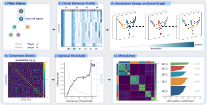

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1a_pipeline.svg


In [4]:
STEM='figure_1a_pipeline'
row=source_manifest.loc[source_manifest['order']==1].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1b_ode_gaussian_variability
Registered source order 2. Byte-identical SVG and PNG; no new scientific calculation.

In [5]:
STEM='figure_1b_ode_gaussian_variability'
row=source_manifest.loc[source_manifest['order']==2].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1b_ode_gaussian_variability.svg


## Retained panel figure_1c_gaussian_noise_four_method
Registered source order 3. Byte-identical SVG and PNG; no new scientific calculation.

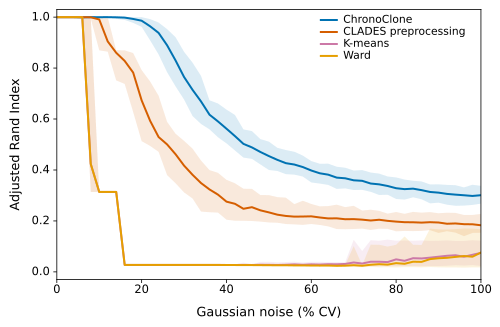

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1c_gaussian_noise_four_method.svg


In [6]:
STEM='figure_1c_gaussian_noise_four_method'
row=source_manifest.loc[source_manifest['order']==3].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1d_uniform_redistribution_four_method
Registered source order 4. Byte-identical SVG and PNG; no new scientific calculation.

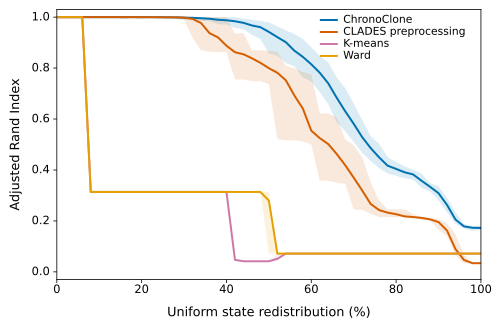

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1d_uniform_redistribution_four_method.svg


In [7]:
STEM='figure_1d_uniform_redistribution_four_method'
row=source_manifest.loc[source_manifest['order']==4].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1e_chronoclone_mean_ari_heatmap_four_method
Registered source order 5. Byte-identical SVG and PNG; no new scientific calculation.

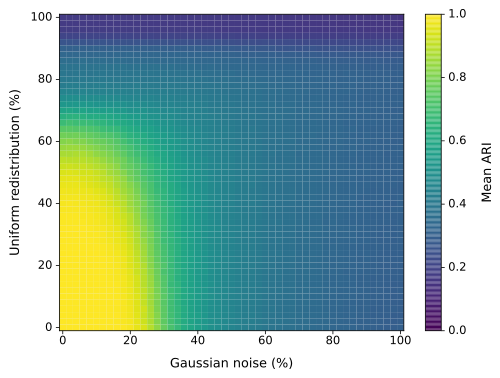

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1e_chronoclone_mean_ari_heatmap_four_method.svg


In [8]:
STEM='figure_1e_chronoclone_mean_ari_heatmap_four_method'
row=source_manifest.loc[source_manifest['order']==5].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1f_clades_preprocessing_mean_ari_heatmap_four_method
Registered source order 6. Byte-identical SVG and PNG; no new scientific calculation.

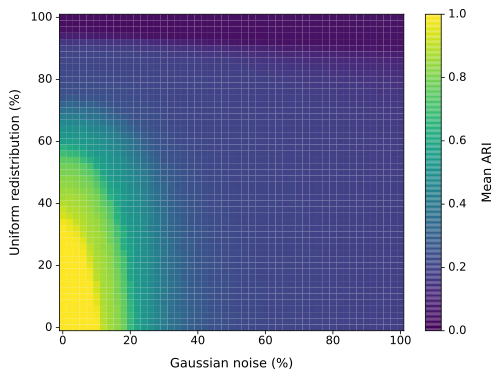

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1f_clades_preprocessing_mean_ari_heatmap_four_method.svg


In [9]:
STEM='figure_1f_clades_preprocessing_mean_ari_heatmap_four_method'
row=source_manifest.loc[source_manifest['order']==6].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1g_kmeans_mean_ari_heatmap_four_method
Registered source order 7. Byte-identical SVG and PNG; no new scientific calculation.

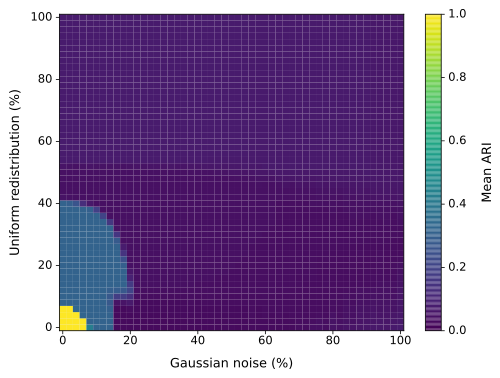

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1g_kmeans_mean_ari_heatmap_four_method.svg


In [10]:
STEM='figure_1g_kmeans_mean_ari_heatmap_four_method'
row=source_manifest.loc[source_manifest['order']==7].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1h_ward_mean_ari_heatmap_four_method
Registered source order 8. Byte-identical SVG and PNG; no new scientific calculation.

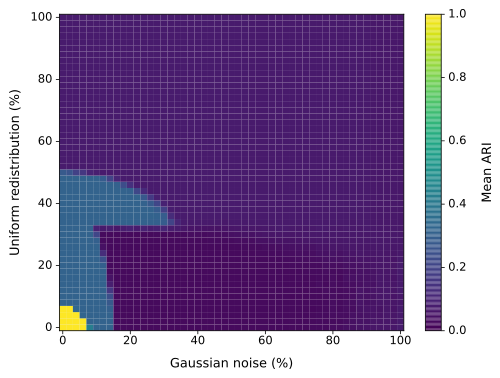

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1h_ward_mean_ari_heatmap_four_method.svg


In [11]:
STEM='figure_1h_ward_mean_ari_heatmap_four_method'
row=source_manifest.loc[source_manifest['order']==8].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Within-day significance on retained distribution figure_2e_neutrophil_pseudotime
The original distribution geometry is retained. Only the requested, clone-level omnibus marks are added; the full twelve-test family is above.

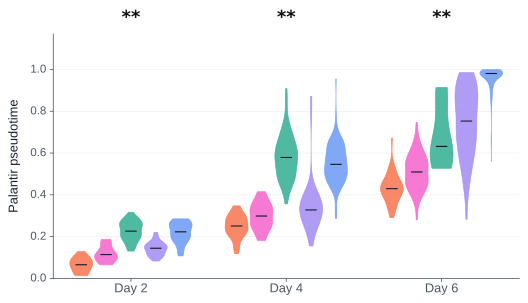

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2e_neutrophil_pseudotime.svg


In [12]:
STEM='figure_2e_neutrophil_pseudotime';context='neutrophil_output'
spec=PSEUDOTIME_TEST_DESIGNS[context]
cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
cells=cells[np.isfinite(cells.pseudotime)]
medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
for test in tests.itertuples():
    values=[medians.loc[(medians.day==test.day)&(medians.metaclone==mc),'pseudotime'].to_numpy() for mc in spec['mcs']]
    supported=[v for v in values if len(v)>=3]
    if test.estimable:assert np.isclose(kruskal(*supported).statistic,test.kruskal_H,rtol=1e-10)
row=source_manifest.loc[source_manifest['order']==13].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
assert rect is not None
axis_top=float(rect.get('y'))
x0,y0,w,h=map(float,root.get('viewBox').split())
symbol_y=y0-12 if 13 in [23,24,25] else axis_top-11
new_top=min(y0,symbol_y-23)
root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
for test in tests.itertuples():
    label_nodes=[node for node in root.iter(NS+'text') if ''.join(node.itertext()).strip()==f'Day {test.day}']
    assert len(label_nodes)==1,(test.day,len(label_nodes))
    label=label_nodes[0]
    if label.get('x') is not None:x=float(label.get('x'))
    else:
        coordinates=re.search(r'translate\(([-+0-9.eE]+)[ ,]+([-+0-9.eE]+)\)',label.get('transform',''))
        assert coordinates is not None,label.attrib
        # These day labels are axis tick labels with centered original anchors.
        x=float(coordinates[1])
        if 'text-anchor: middle' not in label.get('style',''):
            from matplotlib.textpath import TextPath
            size=float(re.search(r'font-size:\s*([0-9.]+)',label.get('style','')).group(1))
            x+=TextPath((0,0),f'Day {test.day}',size=size).get_extents().width/2
    symbol=ET.SubElement(root,NS+'text',{'x':str(x),'y':str(symbol_y),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:18px;font-weight:bold;fill:#111111'})
    symbol.text=test.symbol
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Unchanged distribution geometry; within-day clone-median omnibus symbols, joint 12-test BH family','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel metaclone_key_neutrophil
Registered source order 14. Byte-identical SVG and PNG; no new scientific calculation.

In [13]:
STEM='metaclone_key_neutrophil'
row=source_manifest.loc[source_manifest['order']==14].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/metaclone_key_neutrophil.svg


## Within-day significance on retained distribution figure_2g_monocyte_cell_pseudotime
The original distribution geometry is retained. Only the requested, clone-level omnibus marks are added; the full twelve-test family is above.

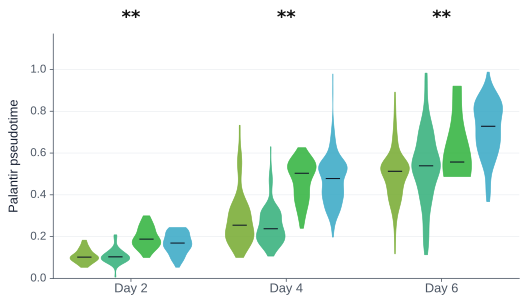

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2g_monocyte_cell_pseudotime.svg


In [14]:
STEM='figure_2g_monocyte_cell_pseudotime';context='monocyte_output'
spec=PSEUDOTIME_TEST_DESIGNS[context]
cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
cells=cells[np.isfinite(cells.pseudotime)]
medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
for test in tests.itertuples():
    values=[medians.loc[(medians.day==test.day)&(medians.metaclone==mc),'pseudotime'].to_numpy() for mc in spec['mcs']]
    supported=[v for v in values if len(v)>=3]
    if test.estimable:assert np.isclose(kruskal(*supported).statistic,test.kruskal_H,rtol=1e-10)
row=source_manifest.loc[source_manifest['order']==16].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
assert rect is not None
axis_top=float(rect.get('y'))
x0,y0,w,h=map(float,root.get('viewBox').split())
symbol_y=y0-12 if 16 in [23,24,25] else axis_top-11
new_top=min(y0,symbol_y-23)
root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
for test in tests.itertuples():
    label_nodes=[node for node in root.iter(NS+'text') if ''.join(node.itertext()).strip()==f'Day {test.day}']
    assert len(label_nodes)==1,(test.day,len(label_nodes))
    label=label_nodes[0]
    if label.get('x') is not None:x=float(label.get('x'))
    else:
        coordinates=re.search(r'translate\(([-+0-9.eE]+)[ ,]+([-+0-9.eE]+)\)',label.get('transform',''))
        assert coordinates is not None,label.attrib
        # These day labels are axis tick labels with centered original anchors.
        x=float(coordinates[1])
        if 'text-anchor: middle' not in label.get('style',''):
            from matplotlib.textpath import TextPath
            size=float(re.search(r'font-size:\s*([0-9.]+)',label.get('style','')).group(1))
            x+=TextPath((0,0),f'Day {test.day}',size=size).get_extents().width/2
    symbol=ET.SubElement(root,NS+'text',{'x':str(x),'y':str(symbol_y),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:18px;font-weight:bold;fill:#111111'})
    symbol.text=test.symbol
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Unchanged distribution geometry; within-day clone-median omnibus symbols, joint 12-test BH family','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel metaclone_key_monocyte
Registered source order 17. Byte-identical SVG and PNG; no new scientific calculation.

In [15]:
STEM='metaclone_key_monocyte'
row=source_manifest.loc[source_manifest['order']==17].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/metaclone_key_monocyte.svg


## Retained panel figure_s3b_clone_recovery
Registered source order 18. Byte-identical SVG and PNG; no new scientific calculation.

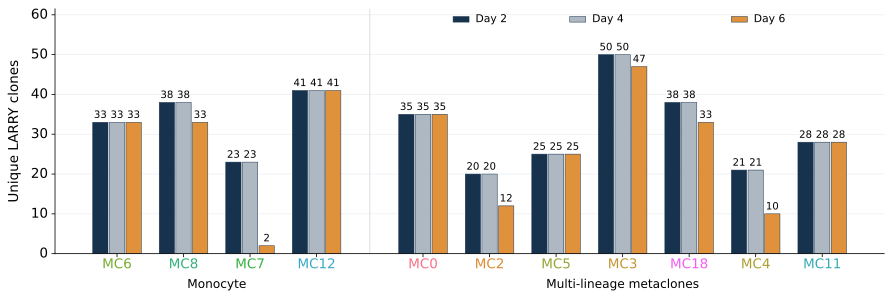

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s3b_clone_recovery.svg


In [16]:
STEM='figure_s3b_clone_recovery'
row=source_manifest.loc[source_manifest['order']==18].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Within-day significance on retained distribution figure_3b_multilineage_baso_pseudotime
The original distribution geometry is retained. Only the requested, clone-level omnibus marks are added; the full twelve-test family is above.

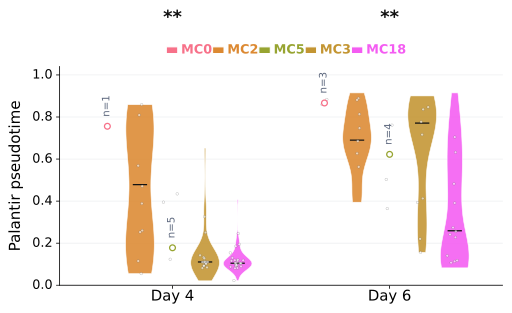

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3b_multilineage_baso_pseudotime.svg


In [17]:
STEM='figure_3b_multilineage_baso_pseudotime';context='multilineage_Baso'
spec=PSEUDOTIME_TEST_DESIGNS[context]
cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
cells=cells[np.isfinite(cells.pseudotime)]
medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
for test in tests.itertuples():
    values=[medians.loc[(medians.day==test.day)&(medians.metaclone==mc),'pseudotime'].to_numpy() for mc in spec['mcs']]
    supported=[v for v in values if len(v)>=3]
    if test.estimable:assert np.isclose(kruskal(*supported).statistic,test.kruskal_H,rtol=1e-10)
row=source_manifest.loc[source_manifest['order']==23].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
assert rect is not None
axis_top=float(rect.get('y'))
x0,y0,w,h=map(float,root.get('viewBox').split())
symbol_y=y0-12 if 23 in [23,24,25] else axis_top-11
new_top=min(y0,symbol_y-23)
root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
for test in tests.itertuples():
    label_nodes=[node for node in root.iter(NS+'text') if ''.join(node.itertext()).strip()==f'Day {test.day}']
    assert len(label_nodes)==1,(test.day,len(label_nodes))
    label=label_nodes[0]
    if label.get('x') is not None:x=float(label.get('x'))
    else:
        coordinates=re.search(r'translate\(([-+0-9.eE]+)[ ,]+([-+0-9.eE]+)\)',label.get('transform',''))
        assert coordinates is not None,label.attrib
        # These day labels are axis tick labels with centered original anchors.
        x=float(coordinates[1])
        if 'text-anchor: middle' not in label.get('style',''):
            from matplotlib.textpath import TextPath
            size=float(re.search(r'font-size:\s*([0-9.]+)',label.get('style','')).group(1))
            x+=TextPath((0,0),f'Day {test.day}',size=size).get_extents().width/2
    symbol=ET.SubElement(root,NS+'text',{'x':str(x),'y':str(symbol_y),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:18px;font-weight:bold;fill:#111111'})
    symbol.text=test.symbol
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Unchanged distribution geometry; within-day clone-median omnibus symbols, joint 12-test BH family','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Within-day significance on retained distribution figure_3c_multilineage_neu_pseudotime
The original distribution geometry is retained. Only the requested, clone-level omnibus marks are added; the full twelve-test family is above.

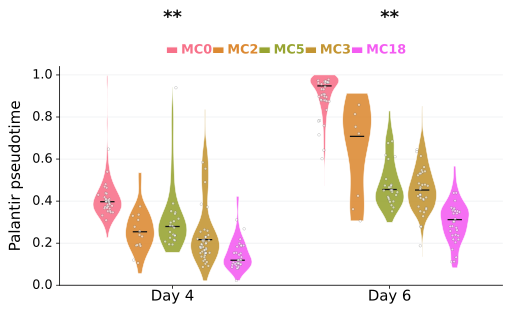

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3c_multilineage_neu_pseudotime.svg


In [18]:
STEM='figure_3c_multilineage_neu_pseudotime';context='multilineage_Neu'
spec=PSEUDOTIME_TEST_DESIGNS[context]
cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
cells=cells[np.isfinite(cells.pseudotime)]
medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
for test in tests.itertuples():
    values=[medians.loc[(medians.day==test.day)&(medians.metaclone==mc),'pseudotime'].to_numpy() for mc in spec['mcs']]
    supported=[v for v in values if len(v)>=3]
    if test.estimable:assert np.isclose(kruskal(*supported).statistic,test.kruskal_H,rtol=1e-10)
row=source_manifest.loc[source_manifest['order']==24].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
assert rect is not None
axis_top=float(rect.get('y'))
x0,y0,w,h=map(float,root.get('viewBox').split())
symbol_y=y0-12 if 24 in [23,24,25] else axis_top-11
new_top=min(y0,symbol_y-23)
root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
for test in tests.itertuples():
    label_nodes=[node for node in root.iter(NS+'text') if ''.join(node.itertext()).strip()==f'Day {test.day}']
    assert len(label_nodes)==1,(test.day,len(label_nodes))
    label=label_nodes[0]
    if label.get('x') is not None:x=float(label.get('x'))
    else:
        coordinates=re.search(r'translate\(([-+0-9.eE]+)[ ,]+([-+0-9.eE]+)\)',label.get('transform',''))
        assert coordinates is not None,label.attrib
        # These day labels are axis tick labels with centered original anchors.
        x=float(coordinates[1])
        if 'text-anchor: middle' not in label.get('style',''):
            from matplotlib.textpath import TextPath
            size=float(re.search(r'font-size:\s*([0-9.]+)',label.get('style','')).group(1))
            x+=TextPath((0,0),f'Day {test.day}',size=size).get_extents().width/2
    symbol=ET.SubElement(root,NS+'text',{'x':str(x),'y':str(symbol_y),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:18px;font-weight:bold;fill:#111111'})
    symbol.text=test.symbol
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Unchanged distribution geometry; within-day clone-median omnibus symbols, joint 12-test BH family','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Within-day significance on retained distribution figure_3d_multilineage_mono_pseudotime
The original distribution geometry is retained. Only the requested, clone-level omnibus marks are added; the full twelve-test family is above.

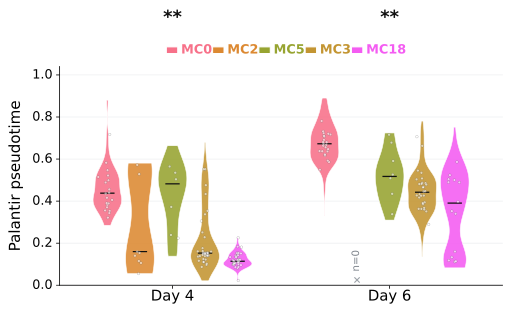

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3d_multilineage_mono_pseudotime.svg


In [19]:
STEM='figure_3d_multilineage_mono_pseudotime';context='multilineage_Mono'
spec=PSEUDOTIME_TEST_DESIGNS[context]
cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
cells=cells[np.isfinite(cells.pseudotime)]
medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
for test in tests.itertuples():
    values=[medians.loc[(medians.day==test.day)&(medians.metaclone==mc),'pseudotime'].to_numpy() for mc in spec['mcs']]
    supported=[v for v in values if len(v)>=3]
    if test.estimable:assert np.isclose(kruskal(*supported).statistic,test.kruskal_H,rtol=1e-10)
row=source_manifest.loc[source_manifest['order']==25].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
assert rect is not None
axis_top=float(rect.get('y'))
x0,y0,w,h=map(float,root.get('viewBox').split())
symbol_y=y0-12 if 25 in [23,24,25] else axis_top-11
new_top=min(y0,symbol_y-23)
root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
for test in tests.itertuples():
    label_nodes=[node for node in root.iter(NS+'text') if ''.join(node.itertext()).strip()==f'Day {test.day}']
    assert len(label_nodes)==1,(test.day,len(label_nodes))
    label=label_nodes[0]
    if label.get('x') is not None:x=float(label.get('x'))
    else:
        coordinates=re.search(r'translate\(([-+0-9.eE]+)[ ,]+([-+0-9.eE]+)\)',label.get('transform',''))
        assert coordinates is not None,label.attrib
        # These day labels are axis tick labels with centered original anchors.
        x=float(coordinates[1])
        if 'text-anchor: middle' not in label.get('style',''):
            from matplotlib.textpath import TextPath
            size=float(re.search(r'font-size:\s*([0-9.]+)',label.get('style','')).group(1))
            x+=TextPath((0,0),f'Day {test.day}',size=size).get_extents().width/2
    symbol=ET.SubElement(root,NS+'text',{'x':str(x),'y':str(symbol_y),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:18px;font-weight:bold;fill:#111111'})
    symbol.text=test.symbol
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Unchanged distribution geometry; within-day clone-median omnibus symbols, joint 12-test BH family','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1i_eligible_fraction_four_method
Registered source order 29. Byte-identical SVG and PNG; no new scientific calculation.

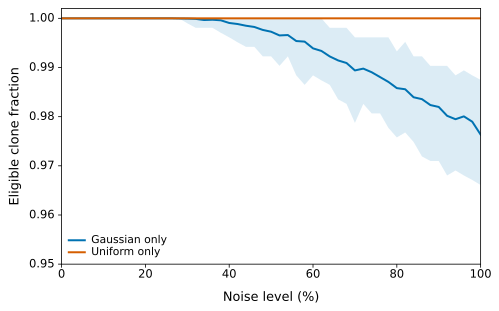

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1i_eligible_fraction_four_method.svg


In [20]:
STEM='figure_1i_eligible_fraction_four_method'
row=source_manifest.loc[source_manifest['order']==29].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_1j_chronoclone_coverage_four_method
Registered source order 30. Byte-identical SVG and PNG; no new scientific calculation.

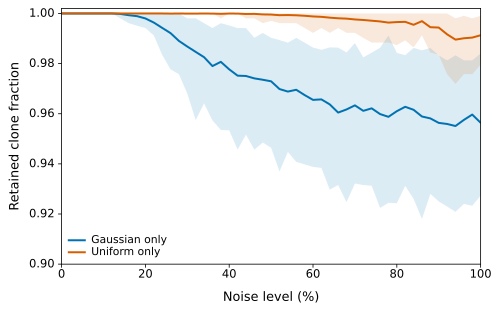

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_1j_chronoclone_coverage_four_method.svg


In [21]:
STEM='figure_1j_chronoclone_coverage_four_method'
row=source_manifest.loc[source_manifest['order']==30].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel program_05_monocyte_all50_row_zscore_heatmap
Registered source order 31. Byte-identical SVG and PNG; no new scientific calculation.

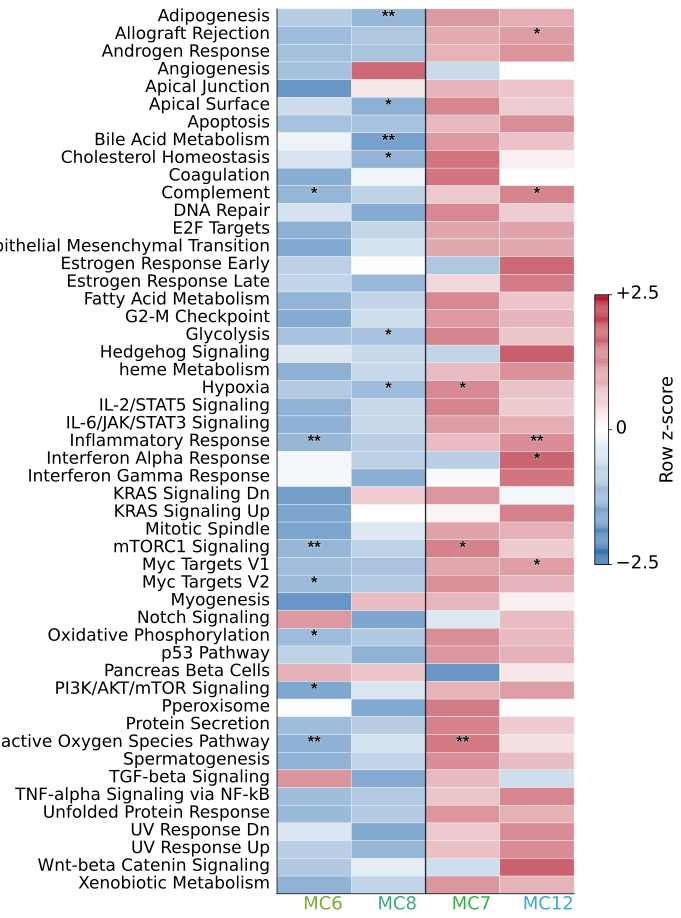

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/program_05_monocyte_all50_row_zscore_heatmap.svg


In [22]:
STEM='program_05_monocyte_all50_row_zscore_heatmap'
row=source_manifest.loc[source_manifest['order']==31].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel program_07_mono_1_gene_contributions
Registered source order 33. Byte-identical SVG and PNG; no new scientific calculation.

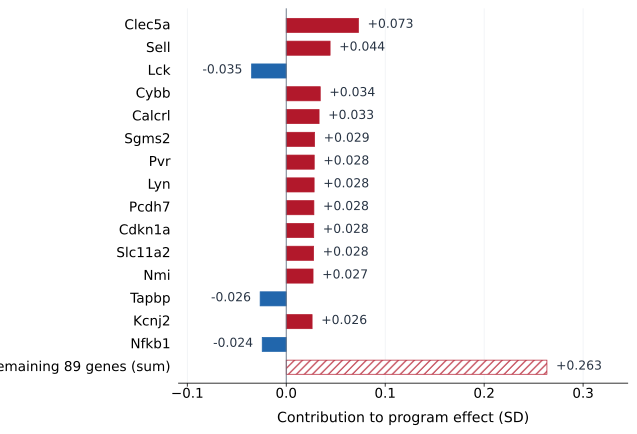

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/program_07_mono_1_gene_contributions.svg


In [23]:
STEM='program_07_mono_1_gene_contributions'
row=source_manifest.loc[source_manifest['order']==33].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Retained panel figure_s5a_cnmf_within_family
Registered source order 38. Byte-identical SVG and PNG; no new scientific calculation.

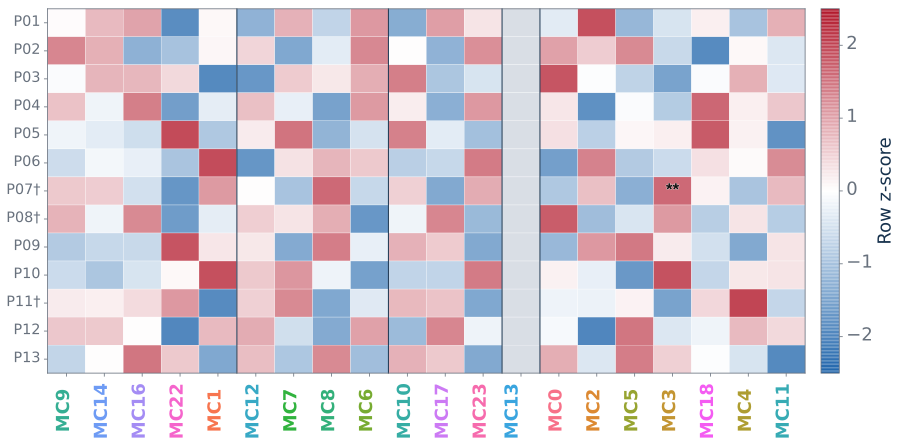

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s5a_cnmf_within_family.svg


In [24]:
STEM='figure_s5a_cnmf_within_family'
row=source_manifest.loc[source_manifest['order']==38].iloc[0]
source_svg=ROOT/row.svg
source_png=ROOT/row.png
shutil.copy2(source_svg,FIG/(STEM+'.svg'))
shutil.copy2(source_png,FIG/(STEM+'.png'))
assert sha256(FIG/(STEM+'.svg'))==row.svg_sha256
assert sha256(FIG/(STEM+'.png'))==row.png_sha256
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'byte-identical retained panel','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Functional labels and registered contrast figure_4a_monocyte_inflammatory_program
Existing marks and axes are retained. Program-distribution panels additionally identify the existing adjusted contrast with brackets and its saved BH significance; the pooled display is not tested against its own constituents.

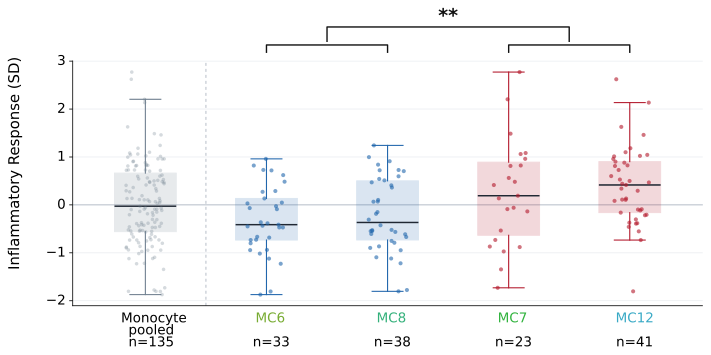

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_4a_monocyte_inflammatory_program.svg


In [25]:
STEM='figure_4a_monocyte_inflammatory_program'
row=source_manifest.loc[source_manifest['order']==20].iloc[0]
source_svg=ROOT/row.svg
tree=ET.parse(source_svg); root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
replacements={'Adjusted program score (SD)':'Inflammatory Response (SD)','Source balancing':'HSPC composition','slower':'','faster':''}
changed=[]
for element in root.iter(NS+'text'):
    content=''.join(element.itertext()).strip()
    if content in replacements and (replacements[content] or content in ['slower','faster']):
        for child in list(element): element.remove(child)
        element.text=replacements[content]; changed.append((content,element.text))
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
assert changed
if 20 in [20,21,27,28]:
    data_file={20:'program_01_mono_1_pooled_and_metaclone_distribution_plot_data.csv',21:'program_02_mono_2_pooled_and_metaclone_distribution_plot_data.csv',27:'program_03_multi_divergence_pooled_and_metaclone_distribution_plot_data.csv',28:'program_04_multi_convergence_pooled_and_metaclone_distribution_plot_data.csv'}[20]
    plot_data=pd.read_csv(ANCESTRY/'tables'/data_file)
    assert plot_data.primary_qvalue.nunique()==1
    assert plot_data.primary_contrast.nunique()==1
    assert plot_data.primary_q_family.nunique()==1
    assert plot_data.groupby('clone_id').size().eq(2).all()
    contrast={20:'Monocyte_fast_minus_slow',21:'Monocyte_fast_minus_slow',27:'MC5_vs_MC3',28:'MC3_vs_MC18'}[20]
    measured_program=plot_data.program.unique()
    assert len(measured_program)==1
    effects=pd.read_csv(ANCESTRY/'tables/primary_program_effects.csv')
    effect=effects[(effects.contrast_id==contrast)&(effects.program==measured_program[0])]
    assert len(effect)==1 and bool(effect.iloc[0].estimable) and bool(effect.iloc[0].support_gate)
    q=float(plot_data.primary_qvalue.iloc[0])
    assert np.isclose(q,effect.iloc[0].qvalue,rtol=1e-10,atol=0)
    mark='**' if q<.05 else '*' if q<.10 else 'ns'
    groups=plot_data[['display_group','display_order']].drop_duplicates().sort_values('display_order')
    order_by_name=groups.set_index('display_group').display_order.to_dict()
    rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
    assert rect is not None
    axis_left,axis_top,axis_width=[float(rect.get(key)) for key in ['x','y','width']]
    positions={name:axis_left+(position+.6)/(len(groups)+.2)*axis_width for name,position in order_by_name.items()}
    reference=['MC6','MC8'] if 20 in [20,21] else ['MC3'] if 20==27 else ['MC18']
    target=['MC7','MC12'] if 20 in [20,21] else ['MC5'] if 20==27 else ['MC3']
    reference_x=[positions[name] for name in reference];target_x=[positions[name] for name in target]
    x0,y0,w,h=map(float,root.get('viewBox').split())
    new_top=min(y0,axis_top-61)
    root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
    annotation=ET.SubElement(root,NS+'g',{'id':'registered-contrast-significance','fill':'none','stroke':'#111111','stroke-width':'1.4'})
    if len(reference)==2:
        for xs in [reference_x,target_x]:
            ET.SubElement(annotation,NS+'polyline',{'points':f'{min(xs)},{axis_top-8} {min(xs)},{axis_top-16} {max(xs)},{axis_top-16} {max(xs)},{axis_top-8}'})
    left,right=sorted([float(np.mean(reference_x)),float(np.mean(target_x))])
    ET.SubElement(annotation,NS+'polyline',{'points':f'{left},{axis_top-19} {left},{axis_top-34} {right},{axis_top-34} {right},{axis_top-19}'})
    text=ET.SubElement(root,NS+'text',{'x':str((left+right)/2),'y':str(axis_top-39),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:19px;font-weight:bold;fill:#111111'})
    text.text=mark
    effect.assign(display_symbol=mark,display_q_family=plot_data.primary_q_family.iloc[0],displayed_contrast=plot_data.primary_contrast.iloc[0]).to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
    changed.append(('registered contrast',str(plot_data.primary_contrast.iloc[0])+'; '+mark))
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':str(changed),'svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Functional labels and registered contrast figure_4b_monocyte_myc_program
Existing marks and axes are retained. Program-distribution panels additionally identify the existing adjusted contrast with brackets and its saved BH significance; the pooled display is not tested against its own constituents.

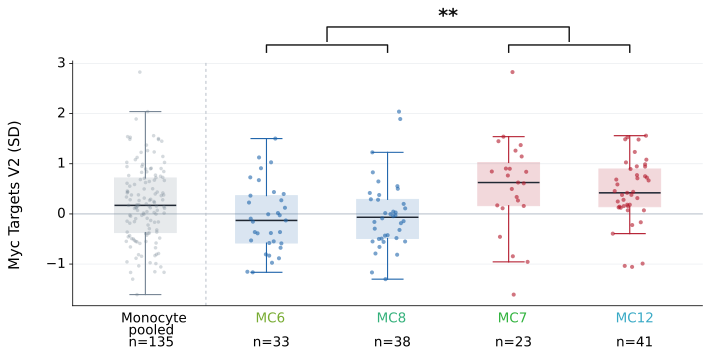

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_4b_monocyte_myc_program.svg


In [26]:
STEM='figure_4b_monocyte_myc_program'
row=source_manifest.loc[source_manifest['order']==21].iloc[0]
source_svg=ROOT/row.svg
tree=ET.parse(source_svg); root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
replacements={'Adjusted program score (SD)':'Myc Targets V2 (SD)','Source balancing':'HSPC composition','slower':'','faster':''}
changed=[]
for element in root.iter(NS+'text'):
    content=''.join(element.itertext()).strip()
    if content in replacements and (replacements[content] or content in ['slower','faster']):
        for child in list(element): element.remove(child)
        element.text=replacements[content]; changed.append((content,element.text))
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
assert changed
if 21 in [20,21,27,28]:
    data_file={20:'program_01_mono_1_pooled_and_metaclone_distribution_plot_data.csv',21:'program_02_mono_2_pooled_and_metaclone_distribution_plot_data.csv',27:'program_03_multi_divergence_pooled_and_metaclone_distribution_plot_data.csv',28:'program_04_multi_convergence_pooled_and_metaclone_distribution_plot_data.csv'}[21]
    plot_data=pd.read_csv(ANCESTRY/'tables'/data_file)
    assert plot_data.primary_qvalue.nunique()==1
    assert plot_data.primary_contrast.nunique()==1
    assert plot_data.primary_q_family.nunique()==1
    assert plot_data.groupby('clone_id').size().eq(2).all()
    contrast={20:'Monocyte_fast_minus_slow',21:'Monocyte_fast_minus_slow',27:'MC5_vs_MC3',28:'MC3_vs_MC18'}[21]
    measured_program=plot_data.program.unique()
    assert len(measured_program)==1
    effects=pd.read_csv(ANCESTRY/'tables/primary_program_effects.csv')
    effect=effects[(effects.contrast_id==contrast)&(effects.program==measured_program[0])]
    assert len(effect)==1 and bool(effect.iloc[0].estimable) and bool(effect.iloc[0].support_gate)
    q=float(plot_data.primary_qvalue.iloc[0])
    assert np.isclose(q,effect.iloc[0].qvalue,rtol=1e-10,atol=0)
    mark='**' if q<.05 else '*' if q<.10 else 'ns'
    groups=plot_data[['display_group','display_order']].drop_duplicates().sort_values('display_order')
    order_by_name=groups.set_index('display_group').display_order.to_dict()
    rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
    assert rect is not None
    axis_left,axis_top,axis_width=[float(rect.get(key)) for key in ['x','y','width']]
    positions={name:axis_left+(position+.6)/(len(groups)+.2)*axis_width for name,position in order_by_name.items()}
    reference=['MC6','MC8'] if 21 in [20,21] else ['MC3'] if 21==27 else ['MC18']
    target=['MC7','MC12'] if 21 in [20,21] else ['MC5'] if 21==27 else ['MC3']
    reference_x=[positions[name] for name in reference];target_x=[positions[name] for name in target]
    x0,y0,w,h=map(float,root.get('viewBox').split())
    new_top=min(y0,axis_top-61)
    root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
    annotation=ET.SubElement(root,NS+'g',{'id':'registered-contrast-significance','fill':'none','stroke':'#111111','stroke-width':'1.4'})
    if len(reference)==2:
        for xs in [reference_x,target_x]:
            ET.SubElement(annotation,NS+'polyline',{'points':f'{min(xs)},{axis_top-8} {min(xs)},{axis_top-16} {max(xs)},{axis_top-16} {max(xs)},{axis_top-8}'})
    left,right=sorted([float(np.mean(reference_x)),float(np.mean(target_x))])
    ET.SubElement(annotation,NS+'polyline',{'points':f'{left},{axis_top-19} {left},{axis_top-34} {right},{axis_top-34} {right},{axis_top-19}'})
    text=ET.SubElement(root,NS+'text',{'x':str((left+right)/2),'y':str(axis_top-39),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:19px;font-weight:bold;fill:#111111'})
    text.text=mark
    effect.assign(display_symbol=mark,display_q_family=plot_data.primary_q_family.iloc[0],displayed_contrast=plot_data.primary_contrast.iloc[0]).to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
    changed.append(('registered contrast',str(plot_data.primary_contrast.iloc[0])+'; '+mark))
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':str(changed),'svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Functional labels and registered contrast figure_s4d_multilineage_ifn_divergence
Existing marks and axes are retained. Program-distribution panels additionally identify the existing adjusted contrast with brackets and its saved BH significance; the pooled display is not tested against its own constituents.

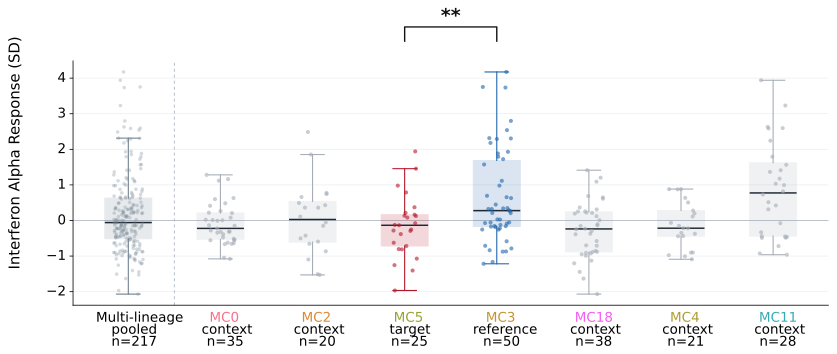

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s4d_multilineage_ifn_divergence.svg


In [27]:
STEM='figure_s4d_multilineage_ifn_divergence'
row=source_manifest.loc[source_manifest['order']==27].iloc[0]
source_svg=ROOT/row.svg
tree=ET.parse(source_svg); root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
replacements={'Adjusted program score (SD)':'Interferon Alpha Response (SD)','Source balancing':'HSPC composition','slower':'','faster':''}
changed=[]
for element in root.iter(NS+'text'):
    content=''.join(element.itertext()).strip()
    if content in replacements and (replacements[content] or content in ['slower','faster']):
        for child in list(element): element.remove(child)
        element.text=replacements[content]; changed.append((content,element.text))
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
assert changed
if 27 in [20,21,27,28]:
    data_file={20:'program_01_mono_1_pooled_and_metaclone_distribution_plot_data.csv',21:'program_02_mono_2_pooled_and_metaclone_distribution_plot_data.csv',27:'program_03_multi_divergence_pooled_and_metaclone_distribution_plot_data.csv',28:'program_04_multi_convergence_pooled_and_metaclone_distribution_plot_data.csv'}[27]
    plot_data=pd.read_csv(ANCESTRY/'tables'/data_file)
    assert plot_data.primary_qvalue.nunique()==1
    assert plot_data.primary_contrast.nunique()==1
    assert plot_data.primary_q_family.nunique()==1
    assert plot_data.groupby('clone_id').size().eq(2).all()
    contrast={20:'Monocyte_fast_minus_slow',21:'Monocyte_fast_minus_slow',27:'MC5_vs_MC3',28:'MC3_vs_MC18'}[27]
    measured_program=plot_data.program.unique()
    assert len(measured_program)==1
    effects=pd.read_csv(ANCESTRY/'tables/primary_program_effects.csv')
    effect=effects[(effects.contrast_id==contrast)&(effects.program==measured_program[0])]
    assert len(effect)==1 and bool(effect.iloc[0].estimable) and bool(effect.iloc[0].support_gate)
    q=float(plot_data.primary_qvalue.iloc[0])
    assert np.isclose(q,effect.iloc[0].qvalue,rtol=1e-10,atol=0)
    mark='**' if q<.05 else '*' if q<.10 else 'ns'
    groups=plot_data[['display_group','display_order']].drop_duplicates().sort_values('display_order')
    order_by_name=groups.set_index('display_group').display_order.to_dict()
    rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
    assert rect is not None
    axis_left,axis_top,axis_width=[float(rect.get(key)) for key in ['x','y','width']]
    positions={name:axis_left+(position+.6)/(len(groups)+.2)*axis_width for name,position in order_by_name.items()}
    reference=['MC6','MC8'] if 27 in [20,21] else ['MC3'] if 27==27 else ['MC18']
    target=['MC7','MC12'] if 27 in [20,21] else ['MC5'] if 27==27 else ['MC3']
    reference_x=[positions[name] for name in reference];target_x=[positions[name] for name in target]
    x0,y0,w,h=map(float,root.get('viewBox').split())
    new_top=min(y0,axis_top-61)
    root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
    annotation=ET.SubElement(root,NS+'g',{'id':'registered-contrast-significance','fill':'none','stroke':'#111111','stroke-width':'1.4'})
    if len(reference)==2:
        for xs in [reference_x,target_x]:
            ET.SubElement(annotation,NS+'polyline',{'points':f'{min(xs)},{axis_top-8} {min(xs)},{axis_top-16} {max(xs)},{axis_top-16} {max(xs)},{axis_top-8}'})
    left,right=sorted([float(np.mean(reference_x)),float(np.mean(target_x))])
    ET.SubElement(annotation,NS+'polyline',{'points':f'{left},{axis_top-19} {left},{axis_top-34} {right},{axis_top-34} {right},{axis_top-19}'})
    text=ET.SubElement(root,NS+'text',{'x':str((left+right)/2),'y':str(axis_top-39),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:19px;font-weight:bold;fill:#111111'})
    text.text=mark
    effect.assign(display_symbol=mark,display_q_family=plot_data.primary_q_family.iloc[0],displayed_contrast=plot_data.primary_contrast.iloc[0]).to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
    changed.append(('registered contrast',str(plot_data.primary_contrast.iloc[0])+'; '+mark))
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':str(changed),'svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Functional labels and registered contrast figure_s4e_multilineage_ifn_convergence
Existing marks and axes are retained. Program-distribution panels additionally identify the existing adjusted contrast with brackets and its saved BH significance; the pooled display is not tested against its own constituents.

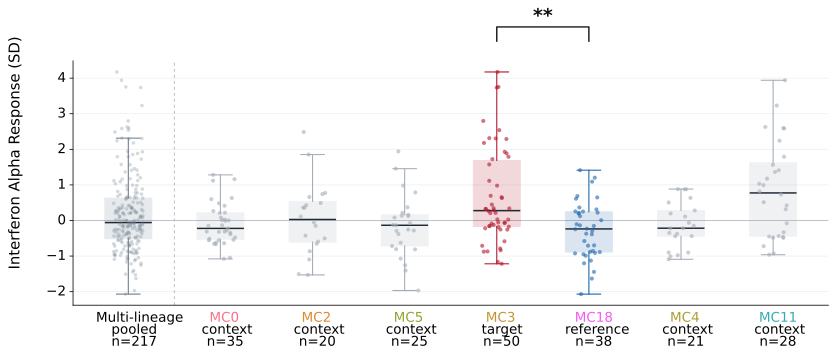

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s4e_multilineage_ifn_convergence.svg


In [28]:
STEM='figure_s4e_multilineage_ifn_convergence'
row=source_manifest.loc[source_manifest['order']==28].iloc[0]
source_svg=ROOT/row.svg
tree=ET.parse(source_svg); root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
replacements={'Adjusted program score (SD)':'Interferon Alpha Response (SD)','Source balancing':'HSPC composition','slower':'','faster':''}
changed=[]
for element in root.iter(NS+'text'):
    content=''.join(element.itertext()).strip()
    if content in replacements and (replacements[content] or content in ['slower','faster']):
        for child in list(element): element.remove(child)
        element.text=replacements[content]; changed.append((content,element.text))
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
assert changed
if 28 in [20,21,27,28]:
    data_file={20:'program_01_mono_1_pooled_and_metaclone_distribution_plot_data.csv',21:'program_02_mono_2_pooled_and_metaclone_distribution_plot_data.csv',27:'program_03_multi_divergence_pooled_and_metaclone_distribution_plot_data.csv',28:'program_04_multi_convergence_pooled_and_metaclone_distribution_plot_data.csv'}[28]
    plot_data=pd.read_csv(ANCESTRY/'tables'/data_file)
    assert plot_data.primary_qvalue.nunique()==1
    assert plot_data.primary_contrast.nunique()==1
    assert plot_data.primary_q_family.nunique()==1
    assert plot_data.groupby('clone_id').size().eq(2).all()
    contrast={20:'Monocyte_fast_minus_slow',21:'Monocyte_fast_minus_slow',27:'MC5_vs_MC3',28:'MC3_vs_MC18'}[28]
    measured_program=plot_data.program.unique()
    assert len(measured_program)==1
    effects=pd.read_csv(ANCESTRY/'tables/primary_program_effects.csv')
    effect=effects[(effects.contrast_id==contrast)&(effects.program==measured_program[0])]
    assert len(effect)==1 and bool(effect.iloc[0].estimable) and bool(effect.iloc[0].support_gate)
    q=float(plot_data.primary_qvalue.iloc[0])
    assert np.isclose(q,effect.iloc[0].qvalue,rtol=1e-10,atol=0)
    mark='**' if q<.05 else '*' if q<.10 else 'ns'
    groups=plot_data[['display_group','display_order']].drop_duplicates().sort_values('display_order')
    order_by_name=groups.set_index('display_group').display_order.to_dict()
    rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
    assert rect is not None
    axis_left,axis_top,axis_width=[float(rect.get(key)) for key in ['x','y','width']]
    positions={name:axis_left+(position+.6)/(len(groups)+.2)*axis_width for name,position in order_by_name.items()}
    reference=['MC6','MC8'] if 28 in [20,21] else ['MC3'] if 28==27 else ['MC18']
    target=['MC7','MC12'] if 28 in [20,21] else ['MC5'] if 28==27 else ['MC3']
    reference_x=[positions[name] for name in reference];target_x=[positions[name] for name in target]
    x0,y0,w,h=map(float,root.get('viewBox').split())
    new_top=min(y0,axis_top-61)
    root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
    annotation=ET.SubElement(root,NS+'g',{'id':'registered-contrast-significance','fill':'none','stroke':'#111111','stroke-width':'1.4'})
    if len(reference)==2:
        for xs in [reference_x,target_x]:
            ET.SubElement(annotation,NS+'polyline',{'points':f'{min(xs)},{axis_top-8} {min(xs)},{axis_top-16} {max(xs)},{axis_top-16} {max(xs)},{axis_top-8}'})
    left,right=sorted([float(np.mean(reference_x)),float(np.mean(target_x))])
    ET.SubElement(annotation,NS+'polyline',{'points':f'{left},{axis_top-19} {left},{axis_top-34} {right},{axis_top-34} {right},{axis_top-19}'})
    text=ET.SubElement(root,NS+'text',{'x':str((left+right)/2),'y':str(axis_top-39),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:19px;font-weight:bold;fill:#111111'})
    text.text=mark
    effect.assign(display_symbol=mark,display_q_family=plot_data.primary_q_family.iloc[0],displayed_contrast=plot_data.primary_contrast.iloc[0]).to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
    changed.append(('registered contrast',str(plot_data.primary_contrast.iloc[0])+'; '+mark))
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':str(changed),'svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Functional labels and registered contrast figure_s5b_cnmf_recovery
Existing marks and axes are retained. Program-distribution panels additionally identify the existing adjusted contrast with brackets and its saved BH significance; the pooled display is not tested against its own constituents.

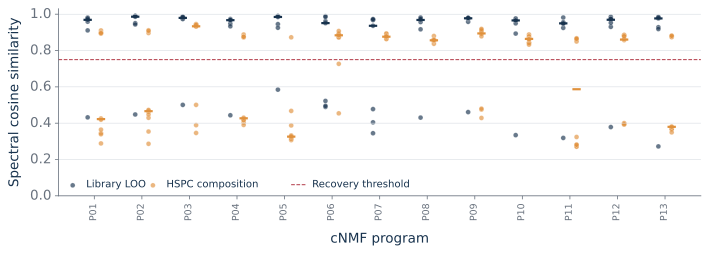

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s5b_cnmf_recovery.svg


In [29]:
STEM='figure_s5b_cnmf_recovery'
row=source_manifest.loc[source_manifest['order']==39].iloc[0]
source_svg=ROOT/row.svg
tree=ET.parse(source_svg); root=tree.getroot()
geometry_before=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
replacements={'Adjusted program score (SD)':'','Source balancing':'HSPC composition','slower':'','faster':''}
changed=[]
for element in root.iter(NS+'text'):
    content=''.join(element.itertext()).strip()
    if content in replacements and (replacements[content] or content in ['slower','faster']):
        for child in list(element): element.remove(child)
        element.text=replacements[content]; changed.append((content,element.text))
geometry_after=[(e.tag,e.get('d'),e.get('x'),e.get('y'),e.get('transform')) for e in root.iter() if e.tag in [NS+'path',NS+'image']]
assert geometry_before==geometry_after
assert changed
if 39 in [20,21,27,28]:
    data_file={20:'program_01_mono_1_pooled_and_metaclone_distribution_plot_data.csv',21:'program_02_mono_2_pooled_and_metaclone_distribution_plot_data.csv',27:'program_03_multi_divergence_pooled_and_metaclone_distribution_plot_data.csv',28:'program_04_multi_convergence_pooled_and_metaclone_distribution_plot_data.csv'}[39]
    plot_data=pd.read_csv(ANCESTRY/'tables'/data_file)
    assert plot_data.primary_qvalue.nunique()==1
    assert plot_data.primary_contrast.nunique()==1
    assert plot_data.primary_q_family.nunique()==1
    assert plot_data.groupby('clone_id').size().eq(2).all()
    contrast={20:'Monocyte_fast_minus_slow',21:'Monocyte_fast_minus_slow',27:'MC5_vs_MC3',28:'MC3_vs_MC18'}[39]
    measured_program=plot_data.program.unique()
    assert len(measured_program)==1
    effects=pd.read_csv(ANCESTRY/'tables/primary_program_effects.csv')
    effect=effects[(effects.contrast_id==contrast)&(effects.program==measured_program[0])]
    assert len(effect)==1 and bool(effect.iloc[0].estimable) and bool(effect.iloc[0].support_gate)
    q=float(plot_data.primary_qvalue.iloc[0])
    assert np.isclose(q,effect.iloc[0].qvalue,rtol=1e-10,atol=0)
    mark='**' if q<.05 else '*' if q<.10 else 'ns'
    groups=plot_data[['display_group','display_order']].drop_duplicates().sort_values('display_order')
    order_by_name=groups.set_index('display_group').display_order.to_dict()
    rect=root.find('.//'+NS+'clipPath/'+NS+'rect')
    assert rect is not None
    axis_left,axis_top,axis_width=[float(rect.get(key)) for key in ['x','y','width']]
    positions={name:axis_left+(position+.6)/(len(groups)+.2)*axis_width for name,position in order_by_name.items()}
    reference=['MC6','MC8'] if 39 in [20,21] else ['MC3'] if 39==27 else ['MC18']
    target=['MC7','MC12'] if 39 in [20,21] else ['MC5'] if 39==27 else ['MC3']
    reference_x=[positions[name] for name in reference];target_x=[positions[name] for name in target]
    x0,y0,w,h=map(float,root.get('viewBox').split())
    new_top=min(y0,axis_top-61)
    root.set('viewBox',f'{x0} {new_top} {w} {h+y0-new_top}');root.set('height',f'{h+y0-new_top}pt')
    annotation=ET.SubElement(root,NS+'g',{'id':'registered-contrast-significance','fill':'none','stroke':'#111111','stroke-width':'1.4'})
    if len(reference)==2:
        for xs in [reference_x,target_x]:
            ET.SubElement(annotation,NS+'polyline',{'points':f'{min(xs)},{axis_top-8} {min(xs)},{axis_top-16} {max(xs)},{axis_top-16} {max(xs)},{axis_top-8}'})
    left,right=sorted([float(np.mean(reference_x)),float(np.mean(target_x))])
    ET.SubElement(annotation,NS+'polyline',{'points':f'{left},{axis_top-19} {left},{axis_top-34} {right},{axis_top-34} {right},{axis_top-19}'})
    text=ET.SubElement(root,NS+'text',{'x':str((left+right)/2),'y':str(axis_top-39),'text-anchor':'middle','style':'font-family:DejaVu Sans;font-size:19px;font-weight:bold;fill:#111111'})
    text.text=mark
    effect.assign(display_symbol=mark,display_q_family=plot_data.primary_q_family.iloc[0],displayed_contrast=plot_data.primary_contrast.iloc[0]).to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
    changed.append(('registered contrast',str(plot_data.primary_contrast.iloc[0])+'; '+mark))
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':str(changed),'svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key figure_2b_selected_metaclone_maps
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

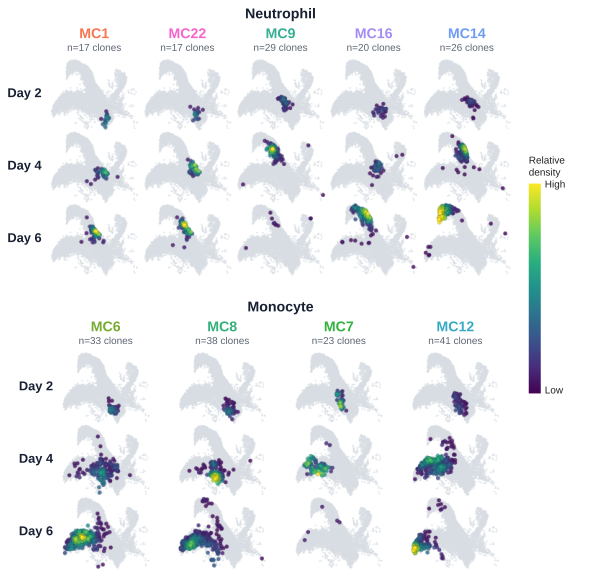

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2b_selected_metaclone_maps.svg


In [30]:
STEM='figure_2b_selected_metaclone_maps'
row=source_manifest.loc[source_manifest['order']==10].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key supplement_all_metaclones_neutrophil
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

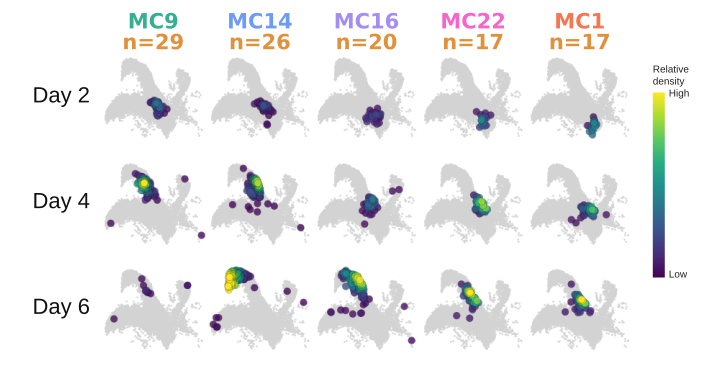

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/supplement_all_metaclones_neutrophil.svg


In [31]:
STEM='supplement_all_metaclones_neutrophil'
row=source_manifest.loc[source_manifest['order']==40].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key supplement_all_metaclones_monocyte
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

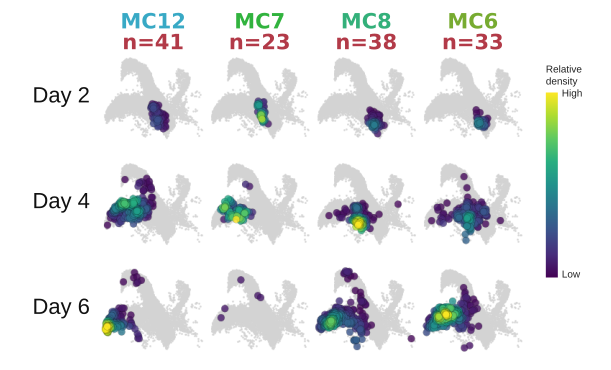

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/supplement_all_metaclones_monocyte.svg


In [32]:
STEM='supplement_all_metaclones_monocyte'
row=source_manifest.loc[source_manifest['order']==41].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key supplement_all_metaclones_erythroid_mk
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

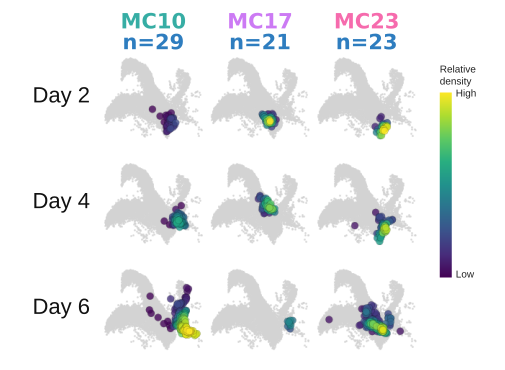

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/supplement_all_metaclones_erythroid_mk.svg


In [33]:
STEM='supplement_all_metaclones_erythroid_mk'
row=source_manifest.loc[source_manifest['order']==42].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key supplement_all_metaclones_basophil
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

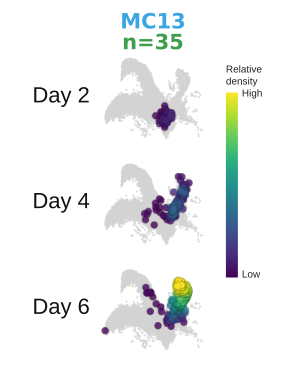

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/supplement_all_metaclones_basophil.svg


In [34]:
STEM='supplement_all_metaclones_basophil'
row=source_manifest.loc[source_manifest['order']==43].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Relative-density key supplement_all_metaclones_multilineage
One inherited analytical panel; unchanged data layer. The integral key identifies its within-metaclone relative density encoding.

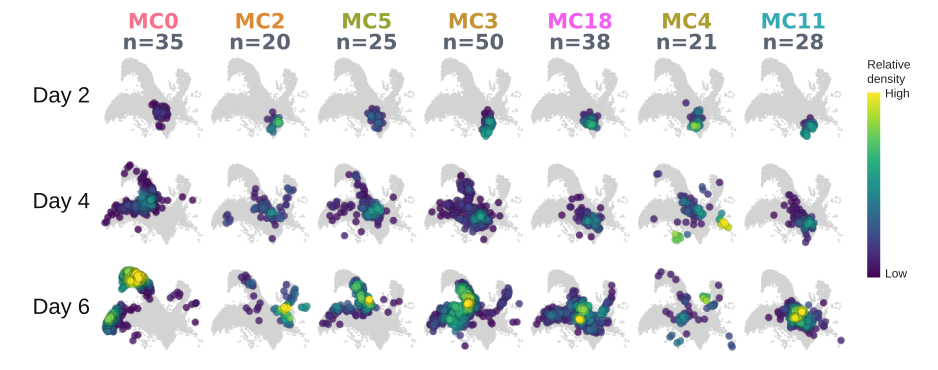

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/supplement_all_metaclones_multilineage.svg


In [35]:
STEM='supplement_all_metaclones_multilineage'
row=source_manifest.loc[source_manifest['order']==44].iloc[0]
tree=ET.parse(ROOT/row.svg);root=tree.getroot()
x0,y0,w,h=map(float,root.get('viewBox').split())
extra=max(75,w*.095)
root.set('viewBox',f'{x0} {y0} {w+extra} {h}')
root.set('width',f'{w+extra}pt');root.set('height',f'{h}pt')
defs=root.find(NS+'defs')
if defs is None: defs=ET.SubElement(root,NS+'defs')
grad=ET.SubElement(defs,NS+'linearGradient',{'id':'densityScale','x1':'0%','y1':'100%','x2':'0%','y2':'0%'})
for i,value in enumerate(np.linspace(0,1,9)):
    ET.SubElement(grad,NS+'stop',{'offset':f'{value*100}%','stop-color':mpl.colors.to_hex(mpl.colormaps['viridis'](value))})
bar_h=min(h*.50,210);bar_y=y0+(h-bar_h)/2;bar_x=x0+w+extra*.13;bar_w=extra*.16
ET.SubElement(root,NS+'rect',{'x':str(bar_x),'y':str(bar_y),'width':str(bar_w),'height':str(bar_h),'fill':'url(#densityScale)'})
font=max(10,w*.014)
for y,text in [(bar_y+font*.4,'High'),(bar_y+bar_h,'Low')]:
    node=ET.SubElement(root,NS+'text',{'x':str(bar_x+bar_w+font*.4),'y':str(y),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'});node.text=text
label=ET.SubElement(root,NS+'text',{'x':str(bar_x),'y':str(bar_y-font*2),'style':f'font-family:Arial;font-size:{font}px;fill:#222222'})
for i,text in enumerate(['Relative','density']):
    span=ET.SubElement(label,NS+'tspan',{'x':str(bar_x),'dy':'0' if i==0 else str(font*1.2)});span.text=text
tree.write(FIG/(STEM+'.svg'),encoding='utf-8',xml_declaration=True)
subprocess.run([NODE,str(OUT/'svg_to_png.mjs'),str(FIG/(STEM+'.svg')),str(FIG/(STEM+'.png'))],check=True,capture_output=True,text=True)
display(SVG(filename=str(FIG/(STEM+'.svg'))))
panel_records.append({'stem':STEM,'source':row.svg,'source_sha256':row.svg_sha256,'change':'Added integral relative-density key; original marks unchanged','svg_sha256':sha256(FIG/(STEM+'.svg')),'png_sha256':sha256(FIG/(STEM+'.png'))})
print(FIG/(STEM+'.svg'))

## Common cellular nomenclature and palette
HSPC labels are pooled for presentation only. Existing metaclone assignments,
stored coordinates and historical distance calculations remain unchanged.
This map is shared by the landscape and composition panels.

In [36]:
STATE_LABELS={'prog_1':'HSPCs','prog_2':'HSPCs','prog_3':'Prog 3','prog_4':'Prog 4','early_prog_Neu':'Early Neu prog','prog_Neu':'Neu prog','prog_Mono':'Mono prog','prog_Baso_Eos':'Baso/Eos prog','prog_Baso_Meg_Ery_Mast':'Baso/Mk/Ery/Mast prog','prog_DC_Mono':'DC/Mono prog','prog_Ly_pDC':'Ly/pDC prog','prog_Meg_Ery':'Mk/Ery prog','Meg':'Mk'}
DISPLAY_COLORS={'HSPCs':'#787878','Prog 3':'#a7a7a7','Prog 4':'#c5c5c5','Neu':'#ec8b23','Early Neu prog':'#f3c685','Neu prog':'#f3a84d','Mono':'#c83f59','Mono prog':'#e8879b','DC/Mono prog':'#b55d76','Baso':'#289646','Baso/Eos prog':'#78bd85','Baso/Mk/Ery/Mast prog':'#8cc493','Ery':'#408bc0','Mk':'#2664a7','Mk/Ery prog':'#89b6d5','Mast':'#874dad','Eos':'#8f663e','DC':'#776792','Ly':'#259994','Ly/pDC prog':'#85c5bf'}
STATE_STAGES={
    'HSPCs and early progenitors':['HSPCs','Prog 3','Prog 4'],
    'Multilineage-associated progenitors':['Baso/Mk/Ery/Mast prog','Ly/pDC prog','DC/Mono prog','Mk/Ery prog','Baso/Eos prog'],
    'Lineage-associated progenitors':['Early Neu prog','Neu prog','Mono prog'],
    'Differentiated cells':['Baso','DC','Eos','Ery','Ly','Mast','Mk','Mono','Neu'],
}
display_order=list(dict.fromkeys(STATE_LABELS.get(s,s) for s in state_order))
assert set(display_order)==set(DISPLAY_COLORS)
pd.DataFrame({'label':display_order,'color':[DISPLAY_COLORS[x] for x in display_order]}).to_csv(OUT/'tables/cell_state_display_palette.csv',index=False)
display(pd.DataFrame({'label':display_order,'color':[DISPLAY_COLORS[x] for x in display_order]}))

,label,color
0,Baso,#289646
1,DC,#776792
2,Eos,#8f663e
3,Ery,#408bc0
4,Ly,#259994
5,Mast,#874dad
6,Mk,#2664a7
7,Mono,#c83f59
8,Neu,#ec8b23
9,Early Neu prog,#f3c685


## HSPC-pooled landscape
Question: where are the biological compartments on the inherited landscape? One categorical scatter with an integral complete key; no new embedding.

{'source_notebook': 'reference_workspace/notebooks/Figure2_klein_pace.ipynb',
 'source_notebook_sha256': '8f653511b3de1c38f044438f6dff00970cbecf47f6e619add63ee36a55935207',
 'original_figsize_inches': (8.6, 6.4),
 'original_marker_area_pt2': 20.0,
 'current_figsize_inches': (9.2, 7.0),
 'current_marker_area_pt2': 22.888047593293667,
 'area_increase_relative_to_previous_panel': 5.722011898323417,
 'alpha': 0.85,
 'rule': 'Preserve marker diameter divided by nominal figure width'}

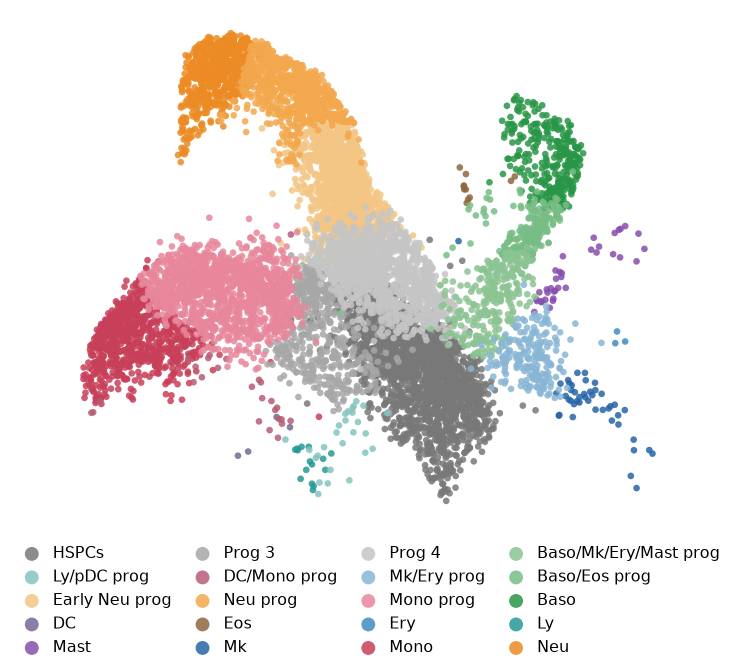

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2a_hspc_landscape.svg


In [37]:
STEM='figure_2a_hspc_landscape'
source=ROOT/'reference_workspace/Figure/fig2/data/fig2a_celltype_umap.csv'
legend_snapshot=OUT/'pre_edit_snapshot/figure_2a_before_legend_order'
legend_snapshot.mkdir(exist_ok=True)
for extension in ['svg','png']:
    prior=FIG/f'{STEM}.{extension}'
    if prior.exists() and not (legend_snapshot/prior.name).exists():shutil.copy2(prior,legend_snapshot/prior.name)
snapshot=OUT/'pre_edit_snapshot/figure_2a_before_marker_restoration'
snapshot.mkdir(exist_ok=True)
for extension in ['svg','png']:
    prior=FIG/f'{STEM}.{extension}'
    if prior.exists() and not (snapshot/prior.name).exists():
        shutil.copy2(prior,snapshot/prior.name)
plot_data=pd.read_csv(source)
assert len(plot_data)==len(obs)
plot_data['display_state']=plot_data.cell_type.replace(STATE_LABELS)
assert not plot_data.display_state.str.match(r'prog_[12]$').any()
assert plot_data[plot_data.cell_type.isin(['prog_1','prog_2'])].shape[0]==plot_data[plot_data.display_state=='HSPCs'].shape[0]
reference_notebook=ROOT/'reference_workspace/notebooks/Figure2_klein_pace.ipynb'
reference_cells=json.loads(reference_notebook.read_text())['cells']
reference_cell=next(''.join(cell['source']) for cell in reference_cells if 'panel_2a_celltype_umap.svg' in ''.join(cell.get('source',[])))
assert 'figsize=(8.6,6.4)' in reference_cell and 's=20' in reference_cell and 'alpha=0.85' in reference_cell
original_figsize=(8.6,6.4)
original_dot_area=20.0
figsize=(9.2,7.0)
# Matplotlib s is area in points squared. Preserve the original diameter-to-
# figure-width ratio; scaling s linearly would shrink dots at the wider size.
dot_area=original_dot_area*(figsize[0]/original_figsize[0])**2
assert np.isclose(np.sqrt(dot_area)/figsize[0],np.sqrt(original_dot_area)/original_figsize[0])
marker_policy={'source_notebook':str(reference_notebook.relative_to(ROOT)),'source_notebook_sha256':sha256(reference_notebook),'original_figsize_inches':original_figsize,'original_marker_area_pt2':original_dot_area,'current_figsize_inches':figsize,'current_marker_area_pt2':dot_area,'area_increase_relative_to_previous_panel':dot_area/4,'alpha':.85,'rule':'Preserve marker diameter divided by nominal figure width'}
(OUT/'reports/figure_2a_marker_policy.json').write_text(json.dumps(marker_policy,indent=2))
display(marker_policy)
fig,ax=plt.subplots(figsize=figsize)
fig.subplots_adjust(left=.035,right=.98,top=.985,bottom=.25)
for state in display_order:
    part=plot_data[plot_data.display_state==state]
    ax.scatter(part.UMAP1,part.UMAP2,s=dot_area,color=DISPLAY_COLORS[state],edgecolors='none',alpha=.85,label=state,rasterized=False)
ax.set_aspect('equal');ax.set_axis_off()
legend_order=[state for states in STATE_STAGES.values() for state in states]
assert len(legend_order)==len(display_order) and set(legend_order)==set(display_order)
handles,labels=ax.get_legend_handles_labels()
handle_by_label=dict(zip(labels,handles))
# Matplotlib fills legend columns; transpose the supplied handles so the
# displayed order reads left to right, then top to bottom, as in Figure 3A.
legend_indices=[i for column in range(4) for i in range(column,len(legend_order),4)]
legend=ax.legend([handle_by_label[legend_order[i]] for i in legend_indices],[legend_order[i] for i in legend_indices],loc='upper center',bbox_to_anchor=(.5,-.015),ncol=4,frameon=False,fontsize=11.2,markerscale=10/np.sqrt(dot_area),handletextpad=.35,columnspacing=1.0)
pd.DataFrame({'display_order':range(1,len(legend_order)+1),'cell_state':legend_order,'legend_row':[i//4+1 for i in range(len(legend_order))],'legend_column':[i%4+1 for i in range(len(legend_order))],'color':[DISPLAY_COLORS[state] for state in legend_order]}).to_csv(OUT/'tables/figure_2a_legend_display_order.csv',index=False)
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Pooled HSPC display; immature-to-mature row-major legend matching Figure 3A; original marker-diameter/figure-width ratio retained; scatter order, colors and coordinates unchanged','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Original Palantir overview requested by the authors
Reproduce the explicitly requested integrated overview from
`reference_workspace/notebooks/Figure2_klein_pace.ipynb`: the pseudotime landscape,
segmented branch arrows, root star and five branch-membership maps.
The user-requested original arrangement is retained as one overview asset;
no new branch fitting, mask estimation, or metaclone calculation is performed.
Original nominal figure dimensions and point areas are retained. Narrative
title text is omitted; functional branch labels and cell counts remain.

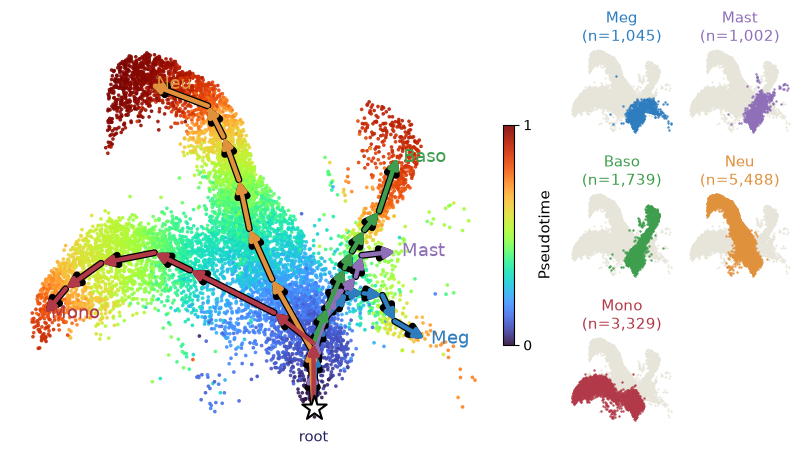

{'source_notebook': 'reference_workspace/notebooks/Figure2_klein_pace.ipynb',
 'source_notebook_sha256': '8f653511b3de1c38f044438f6dff00970cbecf47f6e619add63ee36a55935207',
 'original_figsize_inches': [10.5, 5.2],
 'main_marker_area_pt2': 7,
 'branch_background_marker_area_pt2': 2,
 'branch_foreground_marker_area_pt2': 3,
 'root_marker_area_pt2': 340,
 'marks': 'Source notebook segmented arrows and stored branch masks; no refit',
 'title': 'Narrative title omitted; functional labels retained',
 'svg': 'Editable labels and arrow geometry; dense original scatter layers rasterized'}

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2c_trajectory_overview.svg


In [38]:
STEM='figure_2c_trajectory_overview'
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec
source=ROOT/'reference_workspace/Figure/fig2/data/fig2c_pseudotime_masks.csv'
source_notebook=ROOT/'reference_workspace/notebooks/Figure2_klein_pace.ipynb'
notebook_cells=json.loads(source_notebook.read_text())['cells']
original_cell=next(''.join(c['source']) for c in notebook_cells if c['cell_type']=='code' and 'figsize=(10.5, 5.2)' in ''.join(c['source']) and 'Segmented arrow:' in ''.join(c['source']))
assert 's=7' in original_cell and 's=2' in original_cell and 's=3' in original_cell
snapshot=OUT/'pre_edit_snapshot/figure_2c_before_original_overview'
snapshot.mkdir(exist_ok=True)
for extension in ['svg','png']:
    prior=FIG/f'{STEM}.{extension}'
    if prior.exists() and not (snapshot/prior.name).exists():shutil.copy2(prior,snapshot/prior.name)
plot_data=pd.read_csv(source,index_col='cell')
assert plot_data.index.equals(obs.index)
U=plot_data[['UMAP1','UMAP2']].to_numpy()
ptv=plot_data.pseudotime.to_numpy()
assert np.allclose(U,coordinates['X_umap'])
assert np.allclose(ptv,pd.to_numeric(obs.palantir_pseudotime),equal_nan=True)
branches=['Meg','Mast','Baso','Neu','Mono']
branch_colors={'Mast':'#8E6FB8','Meg':'#2E7DBF','Baso':'#3F9E4D','Neu':'#E0913C','Mono':'#B23A48'}
for branch in branches:assert np.array_equal(plot_data[f'mask_{branch}'].astype(bool),obs[f'mask_{branch}'].astype(bool))
root_i=int(np.nanargmin(ptv));root_xy=U[root_i]
fig=plt.figure(figsize=(10.5,5.2))
grid=gridspec.GridSpec(2,5,figure=fig,width_ratios=[1,1,1,.06,1.35],height_ratios=[1,1],wspace=.12,hspace=.18)
ax=fig.add_subplot(grid[:,0:3])
scatter=ax.scatter(U[:,0],U[:,1],c=ptv,cmap='turbo',s=7,lw=0,alpha=.9,rasterized=True)
waypoint_records=[]
for branch in branches:
    selected=plot_data[f'mask_{branch}'].to_numpy(dtype=bool)
    positions=U[selected];time=ptv[selected]
    edges=np.linspace(np.nanmin(time),np.nanmax(time),8)
    waypoints=[root_xy]
    for left,right in zip(edges[:-1],edges[1:]):
        mask=(time>=left)&(time<right)
        if mask.sum()>=3:
            block=positions[mask]
            waypoints.append(block[np.argmin(((block-np.median(block,axis=0))**2).sum(axis=1))])
    waypoints=np.asarray(waypoints)
    for order,xy in enumerate(waypoints):waypoint_records.append({'branch':branch,'order':order,'UMAP1':xy[0],'UMAP2':xy[1]})
    for start,end in zip(waypoints[:-1],waypoints[1:]):
        ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=17,lw=5.0,color='black',shrinkA=0,shrinkB=0,zorder=4,capstyle='round'))
        ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=14,lw=3.2,color=branch_colors[branch],shrinkA=0,shrinkB=0,zorder=5,capstyle='round'))
    ax.text(waypoints[-1,0],waypoints[-1,1],f' {branch}',fontsize=13,color=branch_colors[branch],va='center',ha='left',zorder=6)
ax.scatter([root_xy[0]],[root_xy[1]],marker='*',s=340,c='white',edgecolors='black',lw=1.5,zorder=7)
ax.text(root_xy[0],root_xy[1]-1.2,'root',fontsize=11,color='#26235F',ha='center',va='top',zorder=7)
ax.set_aspect('equal');ax.set_axis_off()
bar=fig.colorbar(scatter,ax=ax,fraction=.035,pad=.01,shrink=.55)
bar.set_label('Pseudotime',fontsize=11);bar.ax.tick_params(labelsize=10)
bar.set_ticks([ptv.min(),ptv.max()]);bar.set_ticklabels(['0','1'])
right_grid=gridspec.GridSpecFromSubplotSpec(3,2,subplot_spec=grid[:,4],wspace=.08,hspace=.28)
for index,branch in enumerate(branches):
    branch_ax=fig.add_subplot(right_grid[index])
    mask=plot_data[f'mask_{branch}'].to_numpy(dtype=bool)
    branch_ax.scatter(U[~mask,0],U[~mask,1],s=2,c='#E7E4DA',lw=0,rasterized=True)
    branch_ax.scatter(U[mask,0],U[mask,1],s=3,c=branch_colors[branch],lw=0,alpha=.9,rasterized=True)
    branch_ax.set_aspect('equal');branch_ax.set_axis_off()
    branch_ax.set_title(f'{branch}\n(n={mask.sum():,d})',fontsize=11,color=branch_colors[branch],pad=1)
fig.add_subplot(right_grid[5]).set_axis_off()
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv')
pd.DataFrame(waypoint_records).to_csv(OUT/'tables/figure_2c_original_segmented_waypoints.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
policy={'source_notebook':str(source_notebook.relative_to(ROOT)),'source_notebook_sha256':sha256(source_notebook),'original_figsize_inches':[10.5,5.2],'main_marker_area_pt2':7,'branch_background_marker_area_pt2':2,'branch_foreground_marker_area_pt2':3,'root_marker_area_pt2':340,'marks':'Source notebook segmented arrows and stored branch masks; no refit','title':'Narrative title omitted; functional labels retained','svg':'Editable labels and arrow geometry; dense original scatter layers rasterized'}
(OUT/'reports/figure_2c_original_style_policy.json').write_text(json.dumps(policy,indent=2))
display(policy)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'User-requested original integrated overview reproduced from source notebook; original point areas and figsize retained; narrative title omitted','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Complete output-category key figure_2d_neutrophil_output
Existing output proportions are re-displayed without changing their denominator or values. Every category has a visible key.

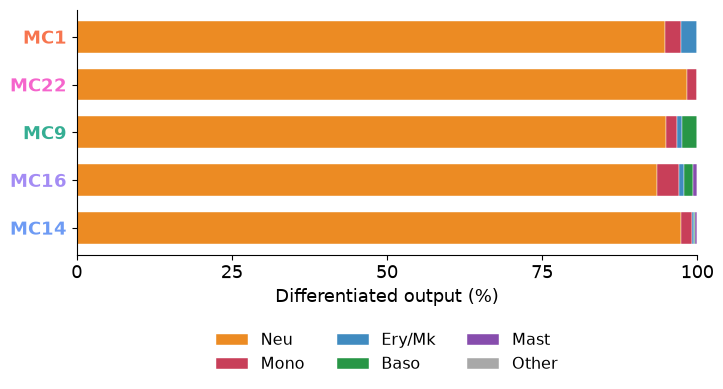

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2d_neutrophil_output.svg


In [39]:
STEM='figure_2d_neutrophil_output'
source=ROOT/'reference_workspace/Figure/fig2/data'/'fig2d_output_composition.csv'
order=[1, 22, 9, 16, 14]
plot_data=pd.read_csv(source).set_index('metaclone').loc[order]
categories=['Neu','Mono','Ery/Mk','Baso','Mast','Other']
assert np.allclose(plot_data[categories].sum(axis=1),1,atol=1e-9)
colors={'Neu':DISPLAY_COLORS['Neu'],'Mono':DISPLAY_COLORS['Mono'],'Ery/Mk':DISPLAY_COLORS['Ery'],'Baso':DISPLAY_COLORS['Baso'],'Mast':DISPLAY_COLORS['Mast'],'Other':'#a8a8a8'}
fig,ax=plt.subplots(figsize=(7.3,3.6))
fig.subplots_adjust(left=.13,right=.98,top=.96,bottom=.28)
y=np.arange(len(order));left=np.zeros(len(order))
for state in categories:
    value=plot_data[state].to_numpy()*100
    ax.barh(y,value,left=left,color=colors[state],height=.66,edgecolor='white',linewidth=.3,label=state)
    left+=value
ax.set_yticks(y,[f'MC{mc}' for mc in order]);ax.invert_yaxis()
for tick,mc in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}']);tick.set_fontweight('bold')
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Differentiated output (%)')
ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,-.26),frameon=False,fontsize=11.5)
plot_data.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Complete category key and shared state palette; proportions unchanged','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Complete output-category key figure_2f_monocyte_output
Existing output proportions are re-displayed without changing their denominator or values. Every category has a visible key.

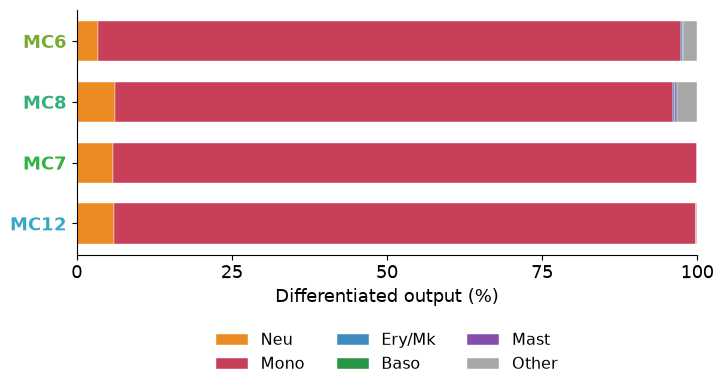

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_2f_monocyte_output.svg


In [40]:
STEM='figure_2f_monocyte_output'
source=ROOT/'reference_workspace/Figure/fig2/data'/'fig2e_output_composition.csv'
order=[6, 8, 7, 12]
plot_data=pd.read_csv(source).set_index('metaclone').loc[order]
categories=['Neu','Mono','Ery/Mk','Baso','Mast','Other']
assert np.allclose(plot_data[categories].sum(axis=1),1,atol=1e-9)
colors={'Neu':DISPLAY_COLORS['Neu'],'Mono':DISPLAY_COLORS['Mono'],'Ery/Mk':DISPLAY_COLORS['Ery'],'Baso':DISPLAY_COLORS['Baso'],'Mast':DISPLAY_COLORS['Mast'],'Other':'#a8a8a8'}
fig,ax=plt.subplots(figsize=(7.3,3.6))
fig.subplots_adjust(left=.13,right=.98,top=.96,bottom=.28)
y=np.arange(len(order));left=np.zeros(len(order))
for state in categories:
    value=plot_data[state].to_numpy()*100
    ax.barh(y,value,left=left,color=colors[state],height=.66,edgecolor='white',linewidth=.3,label=state)
    left+=value
ax.set_yticks(y,[f'MC{mc}' for mc in order]);ax.invert_yaxis()
for tick,mc in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}']);tick.set_fontweight('bold')
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Differentiated output (%)')
ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,-.26),frameon=False,fontsize=11.5)
plot_data.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Complete category key and shared state palette; proportions unchanged','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Multilineage composition with a common HSPC compartment
Existing clone-balanced fractions are summed across the two source HSPC labels. This linear display aggregation does not refit any model or metaclone.

,display_order,cell_state,stage,color
0,1,HSPCs,HSPCs and early progenitors,#787878
1,2,Prog 3,HSPCs and early progenitors,#a7a7a7
2,3,Prog 4,HSPCs and early progenitors,#c5c5c5
3,4,Baso/Mk/Ery/Mast prog,Multilineage-associated progenitors,#8cc493
4,5,Ly/pDC prog,Multilineage-associated progenitors,#85c5bf
5,6,DC/Mono prog,Multilineage-associated progenitors,#b55d76
6,7,Mk/Ery prog,Multilineage-associated progenitors,#89b6d5
7,8,Baso/Eos prog,Multilineage-associated progenitors,#78bd85
8,9,Early Neu prog,Lineage-associated progenitors,#f3c685
9,10,Neu prog,Lineage-associated progenitors,#f3a84d


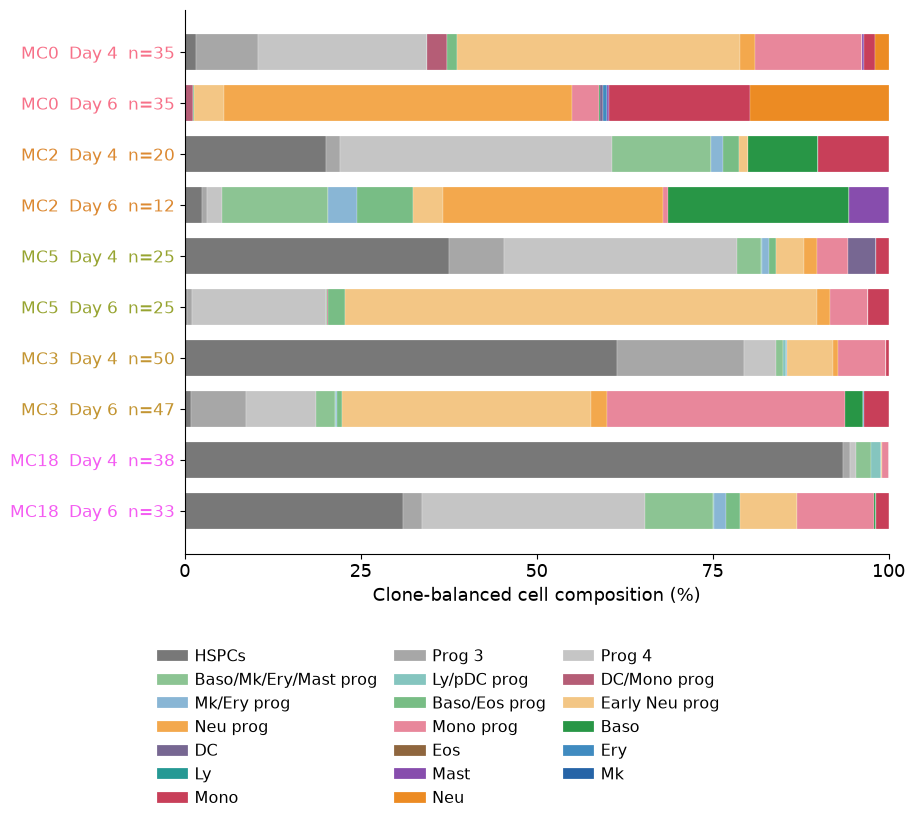

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3a_hspc_pooled_composition.svg


In [41]:
STEM='figure_3a_hspc_pooled_composition'
source=MULTI/'tables/fine_state_composition_clone_balanced.csv'
snapshot=OUT/'pre_edit_snapshot/figure_3a_before_maturation_order'
snapshot.mkdir(exist_ok=True)
for extension in ['svg','png']:
    prior=FIG/f'{STEM}.{extension}'
    if prior.exists() and not (snapshot/prior.name).exists():shutil.copy2(prior,snapshot/prior.name)
original=pd.read_csv(source)
plot_data=original.assign(display_state=original.cell_type.replace(STATE_LABELS)).groupby(['metaclone','day','display_state'],as_index=False).fraction.sum()
order=[(mc,day) for mc in [0,2,5,3,18] for day in [4,6]]
matrix=plot_data.pivot(index=['metaclone','day'],columns='display_state',values='fraction').reindex(index=pd.MultiIndex.from_tuples(order,names=['metaclone','day']),columns=display_order).fillna(0)
assert np.allclose(matrix.sum(axis=1),1,atol=1e-10)
# Annotation-based display hierarchy, not a newly fitted temporal trajectory.
# Terminal cell types share one maturity tier; their within-tier order does
# not claim that one differentiated lineage is more mature than another.
state_stages=STATE_STAGES
stack_order=[state for states in state_stages.values() for state in states]
assert len(stack_order)==len(display_order) and set(stack_order)==set(display_order)
order_table=pd.DataFrame([{'display_order':i+1,'cell_state':state,'stage':next(stage for stage,states in state_stages.items() if state in states),'color':DISPLAY_COLORS[state]} for i,state in enumerate(stack_order)])
order_table.to_csv(OUT/'tables/figure_3a_cell_state_display_order.csv',index=False)
display(order_table)
support=obs[(obs.metaclone.isin([0,2,5,3,18]))&(obs.day.isin([4,6]))].groupby(['metaclone','day']).LARRY_ID.nunique()
fig,ax=plt.subplots(figsize=(9.2,8.0))
fig.subplots_adjust(left=.22,right=.985,top=.98,bottom=.30)
y=np.arange(len(order));left=np.zeros(len(order))
for state in stack_order:
    values=matrix[state].to_numpy()*100
    ax.barh(y,values,left=left,color=DISPLAY_COLORS[state],height=.71,edgecolor='white',linewidth=.15,label=state)
    left+=values
labels=[f'MC{mc}  Day {day}  n={int(support.loc[(mc,day)])}' for mc,day in order]
ax.set_yticks(y,labels,fontsize=12);ax.invert_yaxis()
for tick,(mc,day) in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}'])
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Clone-balanced cell composition (%)')
handles,legend_labels=ax.get_legend_handles_labels()
legend_indices=[i for column in range(3) for i in range(column,len(stack_order),3)]
ax.legend([handles[i] for i in legend_indices],[legend_labels[i] for i in legend_indices],ncol=3,loc='upper center',bbox_to_anchor=(.36,-.15),frameon=False,fontsize=11.3,handletextpad=.4,columnspacing=1.1)
matrix.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Linear HSPC display aggregation; common state palette; immature-to-differentiated left-to-right stacking and row-major legend','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Branch occupancy levels
One heatmap directly shows existing clone-balanced branch fractions at both snapshots, with overlapping branches kept as separate coordinates.

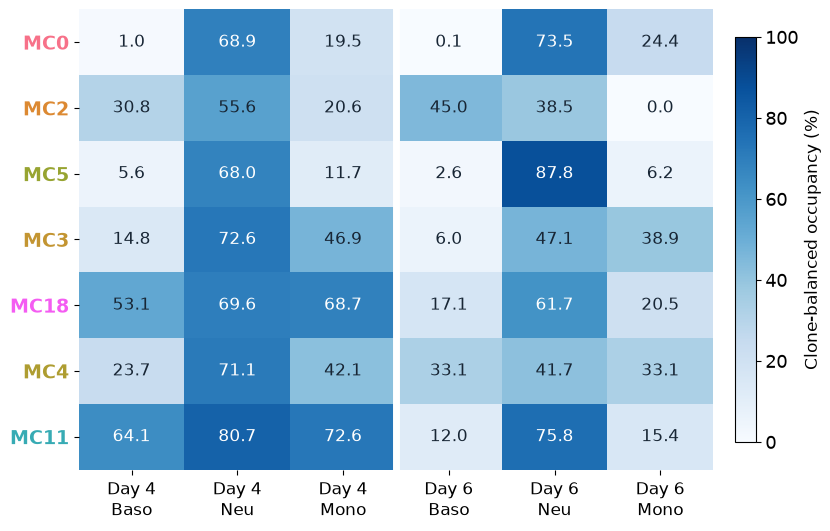

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3c_branch_occupancy_levels.svg


In [42]:
STEM='figure_3c_branch_occupancy_levels'
source=ANCESTRY/'tables/ancestry_03_multilineage_branch_occupancy_change.csv'
table=pd.read_csv(source)
table=table[table.cohort=='day2_hspc_linked'].copy()
order=[0,2,5,3,18,4,11]
cols=[(day,branch) for day in [4,6] for branch in ['Baso','Neu','Mono']]
matrix=np.array([[float(table[(table.metaclone==mc)&(table.branch==branch)][f'day{day}_fraction'].iloc[0])*100 for day,branch in cols] for mc in order])
assert np.isfinite(matrix).all() and (matrix>=0).all() and (matrix<=100).all()
fig,ax=plt.subplots(figsize=(8.2,5.2),layout='constrained')
im=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=100,aspect='auto')
ax.set_xticks(range(6),[f'Day {day}\n{branch}' for day,branch in cols],fontsize=12.5)
ax.set_yticks(range(7),[f'MC{mc}' for mc in order],fontsize=14)
for tick,mc in zip(ax.get_yticklabels(),order):tick.set_color(PALETTE[f'MC{mc}']);tick.set_fontweight('bold')
ax.axvline(2.5,color='white',linewidth=5)
for y in range(7):
    for x in range(6): ax.text(x,y,f'{matrix[y,x]:.1f}',ha='center',va='center',color='white' if matrix[y,x]>58 else '#182635',fontsize=12.2)
cbar=fig.colorbar(im,ax=ax,pad=.035,shrink=.88)
cbar.set_label('Clone-balanced occupancy (%)',fontsize=12)
for spine in ax.spines.values():spine.set_visible(False)
pd.DataFrame(matrix,index=[f'MC{x}' for x in order],columns=[f'Day{d}_{b}' for d,b in cols]).to_csv(OUT/'tables'/f'{STEM}.csv')
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Direct display of existing occupancy levels, no new inference','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Pairwise temporal comparison
One two-snapshot plot of the two existing clone-balanced distances directly supports the specified convergence/divergence statement.

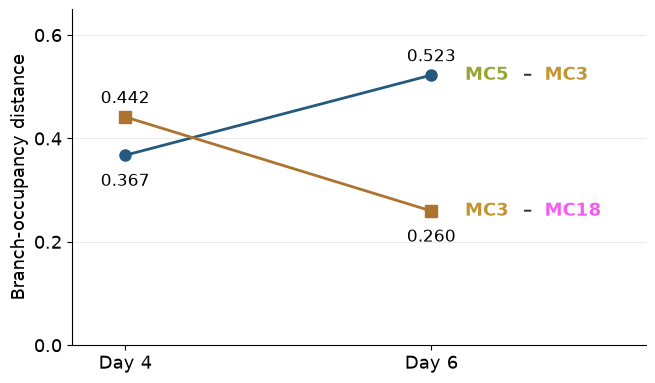

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_3d_branch_pair_distances.svg


In [43]:
STEM='figure_3d_branch_pair_distances'
source=ANCESTRY/'tables/ancestry_multilineage_branch_pair_distances.csv'
table=pd.read_csv(source)
plot_data=table[(table.cohort=='day2_hspc_linked')&(table.estimator=='clone_balanced_occupancy')].copy()
assert len(plot_data)==2
fig,ax=plt.subplots(figsize=(7.0,4.2))
fig.subplots_adjust(left=.16,right=.98,top=.96,bottom=.16)
for (a,b),color,marker in [((5,3),'#245a7e','o'),((3,18),'#ad7430','s')]:
    row=plot_data[(plot_data.metaclone_a==a)&(plot_data.metaclone_b==b)].iloc[0]
    values=[row.day4_distance,row.day6_distance]
    ax.plot([4,6],values,color=color,marker=marker,markersize=8,linewidth=2)
    for x,y in zip([4,6],values):
        offset=10 if (x==4 and a==3) or (x==6 and a==5) else -22
        ax.annotate(f'{y:.3f}',(x,y),xytext=(0,offset),textcoords='offset points',ha='center',fontsize=12)
    ax.text(6.22,values[1],f'MC{a}',color=PALETTE[f'MC{a}'],ha='left',va='center',fontsize=13,fontweight='bold')
    ax.text(6.60,values[1],'–',color='#333333',ha='left',va='center',fontsize=13)
    ax.text(6.74,values[1],f'MC{b}',color=PALETTE[f'MC{b}'],ha='left',va='center',fontsize=13,fontweight='bold')
ax.set_xlim(3.65,7.40);ax.set_ylim(0,.65)
ax.set_xticks([4,6],['Day 4','Day 6']);ax.set_ylabel('Branch-occupancy distance')
ax.set_yticks([0,.2,.4,.6]);ax.grid(axis='y',color='#e8e8e8',linewidth=.6)
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Direct display of previously computed pairwise distances','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## HSPC sensitivity display figure_s4b_monocyte_program_sensitivity
Same stored effects and intervals. The composition-adjusted check remains visible. Restricted-input checks remain in the source record, not recast as distinct biological HSPC types.

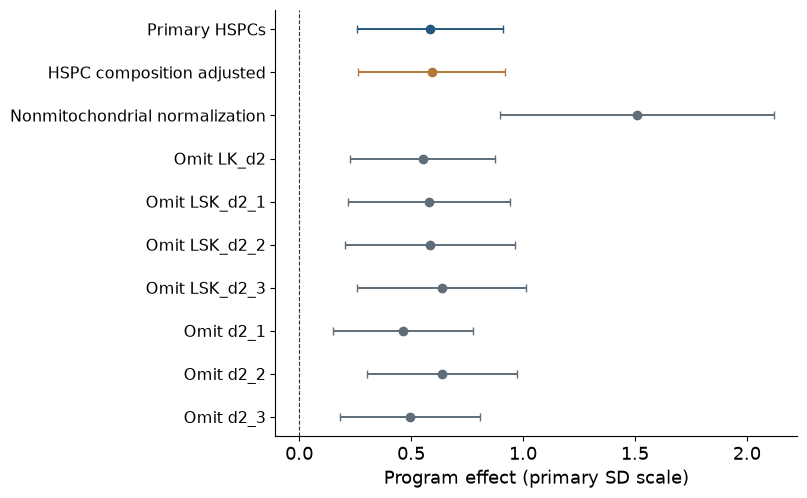

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s4b_monocyte_program_sensitivity.svg


In [44]:
STEM='figure_s4b_monocyte_program_sensitivity'
source=ANCESTRY/'tables'/'program_06_mono_1_sensitivity_forest_plot_data.csv'
table=pd.read_csv(source)
plot_data=table[table.variant!='prog2_only'].sort_values('display_order').copy()
labels=[]
for row in plot_data.itertuples():
    if row.variant=='primary': label='Primary HSPCs'
    elif row.variant=='source_fraction_adjusted':label='HSPC composition adjusted'
    elif row.variant=='nonmito_poscounts':label='Nonmitochondrial normalization'
    else: label='Omit '+row.variant.removeprefix('without_library__')
    labels.append(label)
plot_data['panel_label']=labels
fig,ax=plt.subplots(figsize=(9.0,5.2))
fig.subplots_adjust(left=.40,right=.98,top=.96,bottom=.14)
y=np.arange(len(plot_data))
for i,row in enumerate(plot_data.itertuples()):
    if bool(row.display_supported):
        color='#245a7e' if row.variant=='primary' else '#b17935' if row.variant=='source_fraction_adjusted' else '#5e6d79'
        ax.errorbar(row.effect_primary_scale,i,xerr=[[row.effect_primary_scale-row.ci_low_primary_scale],[row.ci_high_primary_scale-row.effect_primary_scale]],fmt='o',color=color,capsize=3,markersize=6,linewidth=1.4)
    else: ax.text(0,i,'NE',va='center',ha='center',color='#777777')
ax.axvline(0,color='#333333',linewidth=.8,linestyle='--')
ax.set_yticks(y,labels,fontsize=11.5);ax.invert_yaxis()
ax.set_xlabel('Program effect (primary SD scale)')
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Existing sensitivities with HSPC naming; composition check retained','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## HSPC sensitivity display figure_s4f_multilineage_ifn_sensitivity
Same stored effects and intervals. The composition-adjusted check remains visible. Restricted-input checks remain in the source record, not recast as distinct biological HSPC types.

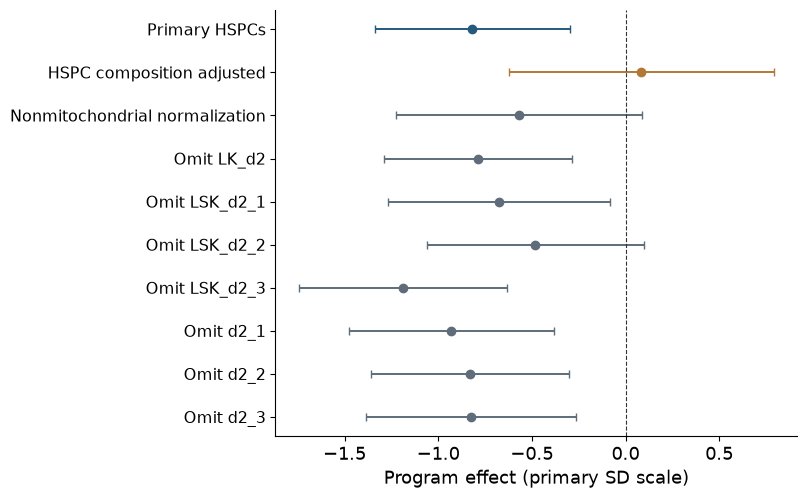

/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s4f_multilineage_ifn_sensitivity.svg


In [45]:
STEM='figure_s4f_multilineage_ifn_sensitivity'
source=ANCESTRY/'tables'/'program_07_multi_divergence_sensitivity_forest_plot_data.csv'
table=pd.read_csv(source)
plot_data=table[table.variant!='prog2_only'].sort_values('display_order').copy()
labels=[]
for row in plot_data.itertuples():
    if row.variant=='primary': label='Primary HSPCs'
    elif row.variant=='source_fraction_adjusted':label='HSPC composition adjusted'
    elif row.variant=='nonmito_poscounts':label='Nonmitochondrial normalization'
    else: label='Omit '+row.variant.removeprefix('without_library__')
    labels.append(label)
plot_data['panel_label']=labels
fig,ax=plt.subplots(figsize=(9.0,5.2))
fig.subplots_adjust(left=.40,right=.98,top=.96,bottom=.14)
y=np.arange(len(plot_data))
for i,row in enumerate(plot_data.itertuples()):
    if bool(row.display_supported):
        color='#245a7e' if row.variant=='primary' else '#b17935' if row.variant=='source_fraction_adjusted' else '#5e6d79'
        ax.errorbar(row.effect_primary_scale,i,xerr=[[row.effect_primary_scale-row.ci_low_primary_scale],[row.ci_high_primary_scale-row.effect_primary_scale]],fmt='o',color=color,capsize=3,markersize=6,linewidth=1.4)
    else: ax.text(0,i,'NE',va='center',ha='center',color='#777777')
ax.axvline(0,color='#333333',linewidth=.8,linestyle='--')
ax.set_yticks(y,labels,fontsize=11.5);ax.invert_yaxis()
ax.set_xlabel('Program effect (primary SD scale)')
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Existing sensitivities with HSPC naming; composition check retained','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Mono clone-level companion
    Re-display the existing Day-2 HSPC-linked clone medians. The monocyte and
    neutrophil companions use identical figure dimensions, marker sizes, axes,
    color rules and median/interquartile marks. Within-day significance reuses
    the corresponding unique test from the declared joint family. Point size and nominal figure size retain the original
    clone-dot panel's ratio. No smoother is fitted to the clone distributions.

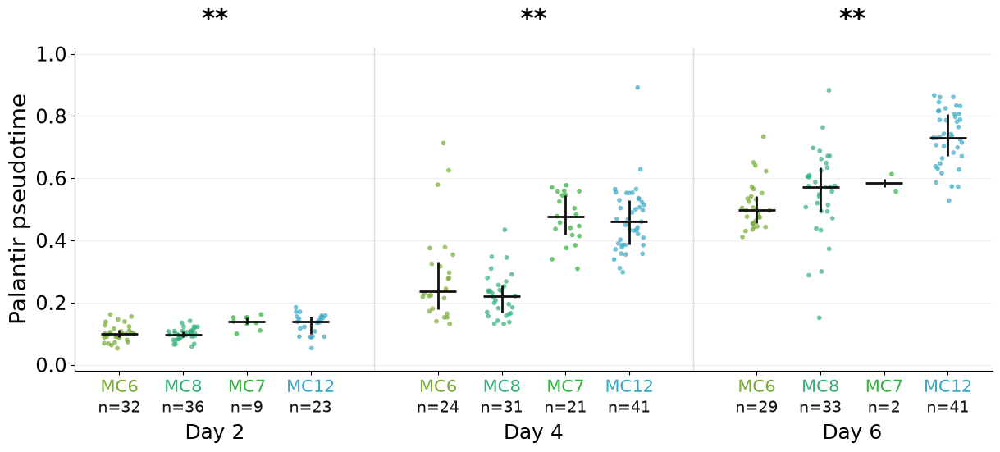

,metaclone,day,x_position,n_observed_clones,n_branch_informative_clones,median_of_clone_medians,lower_quartile,upper_quartile
0,6,2,0,33,32,0.099675,0.087851,0.111519
6,8,2,1,38,36,0.097423,0.089785,0.108407
3,7,2,2,23,9,0.139011,0.130448,0.151850
9,12,2,3,41,23,0.138308,0.099610,0.153763
1,6,4,5,33,24,0.236491,0.178361,0.331951
7,8,4,6,38,31,0.220579,0.167276,0.254515
4,7,4,7,23,21,0.477817,0.417254,0.546028
10,12,4,8,41,41,0.460323,0.385806,0.529449
2,6,6,10,33,29,0.497039,0.454915,0.541730
8,8,6,11,33,33,0.572138,0.493562,0.634302


/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s3a_monocyte_clone_position.svg


In [46]:
STEM='figure_s3a_monocyte_clone_position'
source=ANCESTRY/'tables/ancestry_clone_day_branch_measurements.csv'
branch='Mono';mcs=[6, 8, 7, 12];days=[2,4,6]
registered=pd.read_csv(source)
plot_data=registered[(registered.cohort=='day2_hspc_linked')&(registered.branch==branch)&registered.metaclone.isin(mcs)].copy()
assert set(plot_data.metaclone)==set(mcs)
assert not plot_data.duplicated(['metaclone','LARRY_ID','day']).any()
assert plot_data.day.isin(days).all()
plot_data['mc_order']=plot_data.metaclone.map({mc:i for i,mc in enumerate(mcs)})
plot_data['x_position']=plot_data.day.map({day:i*(len(mcs)+1) for i,day in enumerate(days)})+plot_data.mc_order
plot_data=plot_data.sort_values(['day','mc_order','LARRY_ID'])
summary=plot_data.groupby(['metaclone','day','x_position'],observed=True).agg(n_observed_clones=('LARRY_ID','size'),n_branch_informative_clones=('branch_pseudotime_median','count'),median_of_clone_medians=('branch_pseudotime_median','median'),lower_quartile=('branch_pseudotime_median',lambda v:v.quantile(.25)),upper_quartile=('branch_pseudotime_median',lambda v:v.quantile(.75))).reset_index().sort_values('x_position')
assert len(summary)==len(mcs)*len(days)
if branch=='Mono':
    previous=pd.read_csv(ANCESTRY/'tables/ancestry_02_monocyte_branch_position_summary.csv').sort_values(['metaclone','day']).reset_index(drop=True)
    check=summary.sort_values(['metaclone','day']).reset_index(drop=True)
    for column in ['n_observed_clones','n_branch_informative_clones','median_of_clone_medians','lower_quartile','upper_quartile']:
        assert np.allclose(check[column],previous[column],equal_nan=True),column
context='monocyte_output' if branch=='Mono' else 'neutrophil_output'
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
test_medians=pd.read_csv(OUT/'tables/pseudotime_omnibus_clone_medians.csv')
test_medians=test_medians[test_medians.context==context]
display_medians=plot_data.loc[plot_data.branch_pseudotime_median.notna(),['metaclone','day','LARRY_ID','branch_pseudotime_median']]
matched=display_medians.merge(test_medians,on=['metaclone','day','LARRY_ID'],validate='one_to_one')
assert len(matched)==len(display_medians)==len(test_medians)
assert np.allclose(matched.branch_pseudotime_median,matched.pseudotime)
for test in tests.itertuples():
    arrays=[plot_data.loc[(plot_data.day==test.day)&(plot_data.metaclone==mc),'branch_pseudotime_median'].dropna().to_numpy() for mc in mcs]
    if test.estimable:assert np.isclose(kruskal(*(v for v in arrays if len(v)>=3)).statistic,test.kruskal_H,rtol=1e-10)
fig,ax=plt.subplots(figsize=(12.5,5.4))
fig.subplots_adjust(left=.095,right=.99,top=.98,bottom=.25)
jitter_rng=np.random.default_rng(20260910)
for (mc,day),group in plot_data.groupby(['metaclone','day'],observed=True,sort=True):
    finite=group[group.branch_pseudotime_median.notna()]
    x=float(group.x_position.iloc[0])
    jitter=jitter_rng.uniform(-.24,.24,len(finite))
    ax.scatter(x+jitter,finite.branch_pseudotime_median,s=17,color=PALETTE[f'MC{mc}'],alpha=.70,edgecolors='none',zorder=2)
for row in summary.itertuples():
    if np.isfinite(row.median_of_clone_medians):
        ax.vlines(row.x_position,row.lower_quartile,row.upper_quartile,color='#111111',linewidth=2,zorder=3)
        ax.hlines(row.median_of_clone_medians,row.x_position-.29,row.x_position+.29,color='#111111',linewidth=2,zorder=4)
    ax.text(row.x_position,-.09,f'n={row.n_branch_informative_clones}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=14,color='#111111')
ax.set_xticks(summary.x_position,[f'MC{mc}' for mc in summary.metaclone],fontsize=15)
for tick,mc in zip(ax.get_xticklabels(),summary.metaclone):tick.set_color(PALETTE[f'MC{mc}'])
for i,day in enumerate(days):
    center=i*(len(mcs)+1)+(len(mcs)-1)/2
    ax.text(center,-.21,f'Day {day}',transform=ax.get_xaxis_transform(),ha='center',fontsize=18)
    mark=tests.loc[tests.day==day,'symbol'].item()
    ax.text(center,1.045,mark,transform=ax.get_xaxis_transform(),ha='center',va='bottom',fontsize=22,fontweight='bold',clip_on=False)
    if i<2:ax.axvline(i*(len(mcs)+1)+len(mcs),color='#D8DDE3',linewidth=1)
ax.set_ylim(-.02,1.02);ax.set_xlim(-.7,3*len(mcs)+1.7)
ax.set_ylabel('Palantir pseudotime',fontsize=20);ax.set_yticks(np.linspace(0,1,6));ax.tick_params(axis='y',labelsize=17)
ax.yaxis.grid(True,color='#E6E9EC',linewidth=.6);ax.set_axisbelow(True)
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
summary.to_csv(OUT/'tables'/f'{STEM}_summary.csv',index=False)
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
display(summary)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Matched clone-dot style; unchanged clone medians with the same within-day omnibus significance as the cell violins','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Neu clone-level companion
    Re-display the existing Day-2 HSPC-linked clone medians. The monocyte and
    neutrophil companions use identical figure dimensions, marker sizes, axes,
    color rules and median/interquartile marks. Within-day significance reuses
    the corresponding unique test from the declared joint family. Point size and nominal figure size retain the original
    clone-dot panel's ratio. No smoother is fitted to the clone distributions.

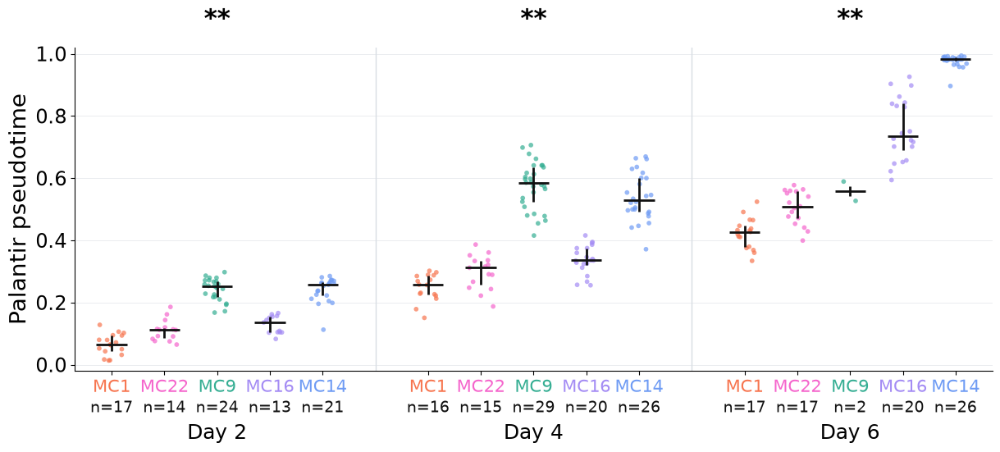

,metaclone,day,x_position,n_observed_clones,n_branch_informative_clones,median_of_clone_medians,lower_quartile,upper_quartile
0,1,2,0,17,17,0.065091,0.043329,0.094075
12,22,2,1,17,14,0.112223,0.085187,0.118730
3,9,2,2,29,24,0.251510,0.218418,0.268999
9,16,2,3,20,13,0.136011,0.104574,0.154607
6,14,2,4,26,21,0.257596,0.222821,0.265803
1,1,4,6,17,16,0.257159,0.225578,0.285911
13,22,4,7,17,15,0.311907,0.257323,0.334903
4,9,4,8,29,29,0.585718,0.524282,0.635082
10,16,4,9,20,20,0.335543,0.321320,0.374908
7,14,4,10,26,26,0.528985,0.492897,0.600543


/path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_weinreb_v3_20260910/figures/figure_s3e_neutrophil_clone_position.svg


In [47]:
STEM='figure_s3e_neutrophil_clone_position'
source=ANCESTRY/'tables/ancestry_clone_day_branch_measurements.csv'
branch='Neu';mcs=[1, 22, 9, 16, 14];days=[2,4,6]
registered=pd.read_csv(source)
plot_data=registered[(registered.cohort=='day2_hspc_linked')&(registered.branch==branch)&registered.metaclone.isin(mcs)].copy()
assert set(plot_data.metaclone)==set(mcs)
assert not plot_data.duplicated(['metaclone','LARRY_ID','day']).any()
assert plot_data.day.isin(days).all()
plot_data['mc_order']=plot_data.metaclone.map({mc:i for i,mc in enumerate(mcs)})
plot_data['x_position']=plot_data.day.map({day:i*(len(mcs)+1) for i,day in enumerate(days)})+plot_data.mc_order
plot_data=plot_data.sort_values(['day','mc_order','LARRY_ID'])
summary=plot_data.groupby(['metaclone','day','x_position'],observed=True).agg(n_observed_clones=('LARRY_ID','size'),n_branch_informative_clones=('branch_pseudotime_median','count'),median_of_clone_medians=('branch_pseudotime_median','median'),lower_quartile=('branch_pseudotime_median',lambda v:v.quantile(.25)),upper_quartile=('branch_pseudotime_median',lambda v:v.quantile(.75))).reset_index().sort_values('x_position')
assert len(summary)==len(mcs)*len(days)
if branch=='Mono':
    previous=pd.read_csv(ANCESTRY/'tables/ancestry_02_monocyte_branch_position_summary.csv').sort_values(['metaclone','day']).reset_index(drop=True)
    check=summary.sort_values(['metaclone','day']).reset_index(drop=True)
    for column in ['n_observed_clones','n_branch_informative_clones','median_of_clone_medians','lower_quartile','upper_quartile']:
        assert np.allclose(check[column],previous[column],equal_nan=True),column
context='monocyte_output' if branch=='Mono' else 'neutrophil_output'
tests=pseudotime_tests[pseudotime_tests.context==context].sort_values('day').copy()
test_medians=pd.read_csv(OUT/'tables/pseudotime_omnibus_clone_medians.csv')
test_medians=test_medians[test_medians.context==context]
display_medians=plot_data.loc[plot_data.branch_pseudotime_median.notna(),['metaclone','day','LARRY_ID','branch_pseudotime_median']]
matched=display_medians.merge(test_medians,on=['metaclone','day','LARRY_ID'],validate='one_to_one')
assert len(matched)==len(display_medians)==len(test_medians)
assert np.allclose(matched.branch_pseudotime_median,matched.pseudotime)
for test in tests.itertuples():
    arrays=[plot_data.loc[(plot_data.day==test.day)&(plot_data.metaclone==mc),'branch_pseudotime_median'].dropna().to_numpy() for mc in mcs]
    if test.estimable:assert np.isclose(kruskal(*(v for v in arrays if len(v)>=3)).statistic,test.kruskal_H,rtol=1e-10)
fig,ax=plt.subplots(figsize=(12.5,5.4))
fig.subplots_adjust(left=.095,right=.99,top=.98,bottom=.25)
jitter_rng=np.random.default_rng(20260910)
for (mc,day),group in plot_data.groupby(['metaclone','day'],observed=True,sort=True):
    finite=group[group.branch_pseudotime_median.notna()]
    x=float(group.x_position.iloc[0])
    jitter=jitter_rng.uniform(-.24,.24,len(finite))
    ax.scatter(x+jitter,finite.branch_pseudotime_median,s=17,color=PALETTE[f'MC{mc}'],alpha=.70,edgecolors='none',zorder=2)
for row in summary.itertuples():
    if np.isfinite(row.median_of_clone_medians):
        ax.vlines(row.x_position,row.lower_quartile,row.upper_quartile,color='#111111',linewidth=2,zorder=3)
        ax.hlines(row.median_of_clone_medians,row.x_position-.29,row.x_position+.29,color='#111111',linewidth=2,zorder=4)
    ax.text(row.x_position,-.09,f'n={row.n_branch_informative_clones}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=14,color='#111111')
ax.set_xticks(summary.x_position,[f'MC{mc}' for mc in summary.metaclone],fontsize=15)
for tick,mc in zip(ax.get_xticklabels(),summary.metaclone):tick.set_color(PALETTE[f'MC{mc}'])
for i,day in enumerate(days):
    center=i*(len(mcs)+1)+(len(mcs)-1)/2
    ax.text(center,-.21,f'Day {day}',transform=ax.get_xaxis_transform(),ha='center',fontsize=18)
    mark=tests.loc[tests.day==day,'symbol'].item()
    ax.text(center,1.045,mark,transform=ax.get_xaxis_transform(),ha='center',va='bottom',fontsize=22,fontweight='bold',clip_on=False)
    if i<2:ax.axvline(i*(len(mcs)+1)+len(mcs),color='#D8DDE3',linewidth=1)
ax.set_ylim(-.02,1.02);ax.set_xlim(-.7,3*len(mcs)+1.7)
ax.set_ylabel('Palantir pseudotime',fontsize=20);ax.set_yticks(np.linspace(0,1,6));ax.tick_params(axis='y',labelsize=17)
ax.yaxis.grid(True,color='#E6E9EC',linewidth=.6);ax.set_axisbelow(True)
plot_data.to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
summary.to_csv(OUT/'tables'/f'{STEM}_summary.csv',index=False)
tests.to_csv(OUT/'tables'/f'{STEM}_significance.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
display(summary)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Matched clone-dot style; unchanged clone medians with the same within-day omnibus significance as the cell violins','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Manuscript and figure integrity

In [48]:
manifest=pd.DataFrame(panel_records)
assert manifest.stem.is_unique
manifest.to_csv(OUT/'reports/panel_manifest.csv',index=False)
text=(OUT/'manuscript_source.md').read_text()
image_names=re.findall(r'!\[.*?\]\(figures/([^)]*)\)',text)
missing=[name for name in image_names if not (FIG/name).is_file()]
print('Manuscript images:',len(image_names),'Generated panel stems:',len(manifest),'Missing:',missing)
assert not missing
assert set(Path(name).stem for name in image_names)==set(manifest.stem)
assert pd.read_csv(OUT/'tables/figure_2a_legend_display_order.csv').cell_state.tolist()==pd.read_csv(OUT/'tables/figure_3a_cell_state_display_order.csv').cell_state.tolist()
for file in FIG.glob('*.svg'):
    root=ET.parse(file).getroot()
    visible=' '.join(''.join(t.itertext()) for t in root.iter(NS+'text'))
    assert not re.search(r'prog[_ ]?[12]\b',visible,re.I),file.name
assert sha256(OLD_MS)=='23c7a92a3d4a78f65d3fbf0020beb258b65076c5f21c53cea51fba75165ca088'
for _,row in source_manifest.iterrows():
    assert sha256(ROOT/row.svg)==row.svg_sha256
    assert sha256(ROOT/row.png)==row.png_sha256
print('Old manuscript and all source panel hashes unchanged.')
display(manifest[['stem','change']])

Manuscript images: 43 Generated panel stems: 43 Missing: []


Old manuscript and all source panel hashes unchanged.


,stem,change
0,figure_1a_pipeline,byte-identical retained panel
1,figure_1b_ode_gaussian_variability,byte-identical retained panel
2,figure_1c_gaussian_noise_four_method,byte-identical retained panel
3,figure_1d_uniform_redistribution_four_method,byte-identical retained panel
4,figure_1e_chronoclone_mean_ari_heatmap_four_me...,byte-identical retained panel
5,figure_1f_clades_preprocessing_mean_ari_heatma...,byte-identical retained panel
6,figure_1g_kmeans_mean_ari_heatmap_four_method,byte-identical retained panel
7,figure_1h_ward_mean_ari_heatmap_four_method,byte-identical retained panel
8,figure_2e_neutrophil_pseudotime,Unchanged distribution geometry; within-day cl...
9,metaclone_key_neutrophil,byte-identical retained panel
